<p><img alt="UdeA logo" height="140px" src="https://upload.wikimedia.org/wikipedia/commons/archive/f/fb/20161010213812%21Escudo-UdeA.svg" align="left" hspace="10px" vspace="0px"></p>
<div align="center">

<h1> <b>Cuatro noches para contar mosquitos</b> </h1>

</div>

<!-- <br> le permite hacer espacios -->
<br>

<hr size=10 noshade color="green">
<p>


<div align="right">

<h3><i> <b>Felipe Quitian Gallego, Miguel Angel Giraldo</b> <br>
Universidad de Antioquia <br>
Instituto de Física  <br>
</i></h3>
</div>

In [ ]:
#Librerias
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
#Figuras
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 10
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

azul, naranja, verde, gris = "#2a78d6", "#eb6834", "#1baf7a", "#8c8c8c"
rng = np.random.default_rng(42)

# 1. Antes de empacar

Antes de abrir las fuentes pensábamos poner 8 trampas, dos en cada uno de cuatro escenarios: cerca y lejos del río, y cerca y lejos de fuentes de contaminación. En cada escenario una trampa iba dentro de la vivienda y otra fuera. La captura sería de 6 horas por noche durante 4 noches, repartidas en bloques de 3, 2 y 1 hora, con 15 minutos de captura en cada hora. El equipo sería de 8 personas y suponíamos 1 mosquito por trampa y por hora:

$$N = \text{trampas}\times\text{horas}\times\text{noches}\times\text{tasa} = 8\times 6\times 4\times 1 = 192.$$

La tasa es el supuesto que más pesa. La dejamos entre 1 mosquito cada 2 horas (96 en total) y 3 por hora (576). Creíamos que lo que más influiría sería la cercanía a agua estancada.

In [ ]:
fermi_central = {"trampas": 8, "horas": 6, "noches": 4, "tasa": 1.0}
fermi_bajo = {"trampas": 8, "horas": 6, "noches": 4, "tasa": 0.5}
fermi_alto = {"trampas": 8, "horas": 6, "noches": 4, "tasa": 3.0}

def total_fermi(p):
    return p["trampas"] * p["horas"] * p["noches"] * p["tasa"]

print("Fermi central", total_fermi(fermi_central), " rango", total_fermi(fermi_bajo), "a", total_fermi(fermi_alto))

Fermi central 192.0  rango 96.0 a 576.0


## 1.1 Por qué cambiamos de perspectiva

Al recibir el dataset vimos que el estudio no se hizo como lo planeamos. No hubo trampas. Dos recolectores capturaban con atrayente humano protegido, con la pierna expuesta desde la rodilla. Uno estaba dentro de la vivienda y otro fuera, y rotaban cada hora, de 17:00 a 5:00 (hasta las 7:00 en la línea base). Con este método solo se capturan hembras, que son las que pican. En Cheté hubo solo dos puntos de captura, Chete 1 y Chete 2, visitados cada mes.

La tabla publicada tampoco trae lo que queríamos medir. No dice si la captura fue dentro o fuera, ni trae la hora, la vivienda, la distancia al agua o la intervención de cada sitio. Con dos puntos no se puede estudiar cómo cambian los mosquitos dentro del poblado, y la cercanía al agua, que era nuestro supuesto principal, no se puede comprobar.

Entonces cambiamos la pregunta. Ya no buscamos dónde poner trampas dentro de Cheté. Preguntamos cuántos mosquitos trae cada punto en cada visita, de qué depende ese número y si se puede predecir la próxima visita. El esfuerzo ya no se mide en horas de trampa sino en horas de recolector. Una noche del estudio son 2 puntos × 2 recolectores × 12 horas = 48 horas de recolector, las mismas 48 horas de nuestras 8 trampas de 6 horas. Son horas nominales: nuestro plan capturaba 15 minutos de cada hora, pero la tasa de 1 por hora la pensamos por hora del plan, así que las dos cuentas se pueden comparar. En la sección 3.5 vemos que lo que falló fue la tasa.

# 2. Cómo se produjeron los datos y qué tan confiables son

Según la descripción del estudio (eml.xml), es un ensayo aleatorizado por conglomerados con dos brazos: mosquiteros con insecticida de larga duración (MILD) y rociado residual dentro de las viviendas (RRI). Tiene una fase de línea base, una de intervención y una de evaluación. Un conglomerado es la unidad que se asigna a un brazo, y en cada uno se capturaba como se describe en la sección 1.1. Los mosquitos se empacaban con el conglomerado, la vivienda, el sitio y la hora, pero solo se publicó el conglomerado, y la tabla no dice qué brazo recibió cada uno. Cargamos los registros y miramos qué columnas traen información.

In [ ]:
z = zipfile.ZipFile("dwca-ins_mosquiteros_malaria-v1.0.zip")
raw = pd.read_csv(z.open("occurrence.txt"), sep="\t", dtype=str)
raw["n"] = raw["individualCount"].astype(int)
print(raw.shape, " mosquitos en total", raw["n"].sum())
print(raw.groupby("scientificName")["n"].sum())

constantes = [c for c in raw.columns if raw[c].nunique() == 1]
print(len(constantes), "columnas con un solo valor")
print(raw["habitat"].unique(), raw["sex"].unique(), raw["eventTime"].unique())

(1502, 69)  mosquitos en total 229394
scientificName
Anopheles albimanus       34424
Anopheles apicimacula       614
Anopheles neivai         194356
Name: n, dtype: int64
31 columnas con un solo valor
<StringArray>
['En domicilio']
Length: 1, dtype: str <StringArray>
['Hembra']
Length: 1, dtype: str <StringArray>
['17:00:00/07:00:00', '17:00:00/05:00:00']
Length: 2, dtype: str


Los totales coinciden con el resumen del estudio en eml.xml: 229394 mosquitos, de ellos 194356 An. neivai, 34424 An. albimanus y 614 An. apicimacula. Cada fila es la suma de una especie en una campaña de un conglomerado, no un mosquito ni una noche. La mayoría de las 69 columnas tiene un solo valor. Por ejemplo, habitat siempre dice En domicilio y todas las filas son hembras.

La tabla trae cosas que no habíamos pensado anotar en nuestra hoja de campo, como quién registra y quién identifica cada captura, el esfuerzo de cada campaña en noches y horas, y la coordenada de cada conglomerado. Le faltan la hora, si la captura fue dentro o fuera, la vivienda y la distancia al agua. Las columnas que cambian y usamos son el conglomerado y la visita (eventID), las fechas, el esfuerzo (samplingEffort), la especie, el conteo, la localidad, el municipio, las coordenadas y las dos columnas de personas. Ahora revisamos los problemas de calidad.

In [ ]:
# fechas vacías y años que no coinciden entre eventDate y verbatimEventDate ("enero 2023")
print((raw["eventDate"].isna()).sum(), "filas sin eventDate")
anio_verbatim = raw["verbatimEventDate"].str.extract(r"^[a-záéíóú]+ (\d{4})$")[0]
anio_evento = raw["eventDate"].str[:4]
distinto = raw[anio_verbatim.notna() & anio_evento.notna() & (anio_verbatim != anio_evento)]
print(distinto[["eventID", "eventDate", "verbatimEventDate", "county"]].drop_duplicates("eventID").to_string())

20 filas sin eventDate
         eventID              eventDate verbatimEventDate    county
392    Sanson-06             2022-09-03   septiembre 2021     Guapi
745   Temuey1-21  2023-02-02/2023-02-22      febrero 2022     Guapi
1303   BrazoC-19  2022-01-12/2022-01-27        enero 2023  Timbiquí
1311  Coteje1-20  2022-01-10/2022-01-25        enero 2023  Timbiquí
1372   BrazoC-20  2022-02-06/2022-02-27      febrero 2023  Timbiquí
1379  Coteje1-21  2022-02-02/2022-02-22      febrero 2023  Timbiquí
1436   BrazoC-21  2022-03-06/2022-03-21        marzo 2023  Timbiquí
1444  Coteje1-22  2022-03-01/2022-03-07        marzo 2023  Timbiquí


In [ ]:
# identificadores, esfuerzo, filas repetidas, taxonomía y coordenadas
print(raw.loc[raw["eventID"].str.contains("_"), "eventID"].unique()[:6])
print(raw["samplingEffort"].value_counts().head(8))
noches_fila = raw["samplingEffort"].str.split(", ").str[1].str.split(" ").str[0].astype(int)
rango = noches_fila.groupby(raw["eventID"]).agg(["min", "max", "size"])
print("campañas con noches distintas entre especies", ((rango["size"] > 1) & (rango["min"] != rango["max"])).sum())
print(len(raw[raw.duplicated(["eventID", "scientificName"], keep=False)]), "filas repetidas para la misma campaña y especie")
print(raw.groupby("scientificName")["subgenus"].value_counts())
print(raw.groupby("verbatimLocality")["county"].nunique().loc[lambda s: s > 1])
print(raw["georeferenceRemarks"].notna().sum(), "filas con aviso en las coordenadas")

<StringArray>
['Mataco_01', 'Saija_1-01', 'Charco_01', 'Saija_3-01', 'BrazoC_01',
 'Coteje1_01']
Length: 6, dtype: str
samplingEffort
12 h por noche, 4 noches    645
12 h por noche, 3 noches    345
12 h por noche, 5 noches    113
12 h por noche, 1 noche     101
12 h por noche, 2 noches     73
14 h por noche, 2 noches     60
14 h por noche, 1 noche      42
14 h por noche, 3 noches     35
Name: count, dtype: int64
campañas con noches distintas entre especies 15
14 filas repetidas para la misma campaña y especie
scientificName         subgenus     
Anopheles albimanus    Nyssorhynchus    504
Anopheles apicimacula  Anopheles        175
Anopheles neivai       Kerteszia        816
                       Anopheles          7
Name: count, dtype: int64
verbatimLocality
Las Peñas    2
Micaelita    2
Name: county, dtype: int64
92 filas con aviso en las coordenadas


La tabla resume los problemas que encontramos en las filas crudas y lo que hicimos con cada uno.

| Problema | Dónde | Qué hicimos |
|---|---|---|
| eventDate vacío. La fecha quedó en verbatimEventDate, a veces con el año final mal escrito (2023-01-10/2022-01-25) | 20 filas | Tomamos la fecha de verbatimEventDate y corregimos el año final cuando queda casi un año antes del inicio |
| El año de eventDate no coincide con el de verbatimEventDate. BrazoC 19 a 21 y Coteje1 20 a 22 dicen 2022 en eventDate y enero a marzo de 2023 en verbatimEventDate | 8 campañas, 6 de Timbiquí | Nos quedamos con el año que respeta el orden de las visitas del conglomerado. Corrige 7 campañas. En Temuey1-21 el error está en verbatimEventDate y se deja como está |
| eventID con guion bajo (Mataco_01) que crea conglomerados falsos en parentEventID | 15 nombres falsos | Reconstruimos el conglomerado desde eventID, de 55 nombres quedan 40 |
| Cada especie trae su propio número de noches dentro de la misma campaña | 15 campañas | Las noches de la campaña son el mayor número entre sus filas |
| Noches de 14 horas en la línea base y unas filas de 7 horas en Guapi | 145 y 5 filas | Medimos el esfuerzo en noches de 12 horas |
| Dos filas para la misma campaña y especie | 7 pares | Las sumamos. Pueden ser dos viviendas o una digitación doble, como Quiroga1-10 con 149 y 149 |
| Subgénero de An. neivai escrito como Anopheles y no Kerteszia | 7 filas | No afecta los conteos |
| Las Peñas y Micaelita aparecen a la vez en Guapi y en Santa Bárbara | 2 localidades | Las dejamos en Santa Bárbara. Solo entran en la sección 3.1 |
| Coordenadas que el SiB marca fuera del municipio, y una misma coordenada repetida en tres conglomerados | 92 filas y 3 sitios | Las coordenadas no entran al modelo. Para el mapa y el PCA elegimos una por conglomerado (sección 2.1) |
| La tabla no trae el brazo de intervención de cada conglomerado ni la fase de cada campaña | todo el archivo | Lo declaramos como limitación. La línea base la identificamos por sus 14 horas, como dice la descripción del estudio |

El error de año es el que más importa. Sin corregirlo, seis campañas de 2023 quedaban como de enero a marzo de 2022, dentro de los datos de entrenamiento, y al conjunto reservado le faltaban campañas. Los demás problemas no cambian el total de mosquitos, pero varios cambian el esfuerzo, y el esfuerzo es lo que usamos para pasar de una campaña a una tasa por noche.

In [ ]:
df = raw.copy()
ev = df["eventID"].str.replace("_", "-")
df["cluster"] = ev.str.rsplit("-", n=1).str[0].str.replace("-", "")
df["visita"] = ev.str.rsplit("-", n=1).str[1].astype(int)

fecha = df["eventDate"].fillna(df["verbatimEventDate"])
df["inicio"] = pd.to_datetime(fecha.str.split("/").str[0])
df["fin"] = pd.to_datetime(fecha.str.split("/").str[-1])

# cuando los dos años no coinciden nos quedamos con el que respeta el orden de las visitas del conglomerado
anio_verbatim = df["verbatimEventDate"].str.extract(r"^[a-záéíóú]+ (\d{4})$")[0].astype(float)
duda = anio_verbatim.notna() & (anio_verbatim != df["inicio"].dt.year)
seguras = df[~duda].groupby(["cluster", "visita"])["inicio"].min()
corregidas = []
for i in df.index[duda]:
    c, v = df.at[i, "cluster"], df.at[i, "visita"]
    fechas_c = seguras[c]
    antes = fechas_c[fechas_c.index < v].max() if (fechas_c.index < v).any() else pd.Timestamp("1900-01-01")
    despues = fechas_c[fechas_c.index > v].min() if (fechas_c.index > v).any() else pd.Timestamp("2100-01-01")
    candidato = df.at[i, "inicio"] + pd.DateOffset(years=int(anio_verbatim[i] - df.at[i, "inicio"].year))
    if antes < candidato < despues:
        df.at[i, "fin"] = df.at[i, "fin"] + (candidato - df.at[i, "inicio"])
        df.at[i, "inicio"] = candidato
        corregidas.append(df.at[i, "eventID"])
print("campañas con el año corregido", sorted(set(corregidas)))

# fechas finales con el año mal escrito, como 2023-01-10/2022-01-25
mal_fin = df["fin"] < df["inicio"] - pd.Timedelta(days=300)
df.loc[mal_fin, "fin"] = df.loc[mal_fin, "fin"] + pd.DateOffset(years=1)

df["horas"] = df["samplingEffort"].str.split(" h").str[0].astype(int)
df["noches"] = noches_fila
df["localidad"] = df["locality"].str.replace("Santa Bárbara, ", "")
df["municipio"] = df["county"]
df.loc[df["localidad"].isin(["Las Peñas", "Micaelita"]), "municipio"] = "Santa Bárbara"
df["especie"] = df["scientificName"].str.replace("Anopheles ", "")
print(df["cluster"].nunique(), "conglomerados", df["localidad"].nunique(), "localidades")

campañas con el año corregido ['BrazoC-19', 'BrazoC-20', 'BrazoC-21', 'Coteje1-20', 'Coteje1-21', 'Coteje1-22', 'Sanson-06']
40 conglomerados 25 localidades


## 2.1 La observación y el esfuerzo

Una observación es una campaña de un conglomerado: la visita de dos recolectores a ese conglomerado durante varias noches, que no son seguidas (en Cheté una campaña de 4 noches se reparte en unos 17 días). No sabemos si cada campaña muestrea una casa o varias. Sumamos las tres especies y las filas repetidas. Como noches de la campaña tomamos el mayor número entre sus filas, porque si una especie no apareció en una noche eso no le resta noches a la campaña. Para comparar campañas de distinta duración definimos

$$\text{esfuerzo} = \text{noches}\times\frac{\text{horas por noche}}{12},\qquad \text{tasa} = \frac{\text{total}}{\text{esfuerzo}},\qquad y = \log_{10}(\text{tasa}+1).$$

La tasa es el número de mosquitos por noche estándar de 12 horas en un punto con dos recolectores. Por ejemplo, la primera campaña de Brazo Corto tuvo 81 mosquitos en 2 noches de 14 horas. Su esfuerzo es 2 × 14/12 = 2.33, su tasa 34.7 y su y = 1.55. Dividir por las horas supone que todas las horas capturan lo mismo, así que en las noches de 14 horas de la línea base el ajuste es aproximado. La columna ltasa guarda y, y en la sección 2.3 explicamos por qué usamos el logaritmo.

In [ ]:
camp = df.groupby(["cluster", "visita"]).agg(
    localidad=("localidad", "first"),
    municipio=("municipio", "first"),
    inicio=("inicio", "min"),
    fin=("fin", "max"),
    noches=("noches", "max"),
    horas=("horas", "max"),
    total=("n", "sum"),
).reset_index()
por_especie = df.pivot_table(index=["cluster", "visita"], columns="especie", values="n", aggfunc="sum", fill_value=0)
camp = camp.merge(por_especie.reset_index(), on=["cluster", "visita"])

camp["fin"] = camp[["inicio", "fin"]].max(axis=1)
camp["esfuerzo"] = camp["noches"] * camp["horas"] / 12
camp["tasa"] = camp["total"] / camp["esfuerzo"]
camp["ltasa"] = np.log10(camp["tasa"] + 1)
camp["mes"] = camp["inicio"].dt.month
camp["ronda"] = camp["inicio"].dt.to_period("M")
camp["linea_base"] = camp["horas"] == 14   # la descripción dice que la línea base duró 14 horas por noche

# coordenadas: algunos conglomerados comparten la coordenada de otro; preferimos la que es solo suya
uso = df.groupby(["cluster", "decimalLatitude", "decimalLongitude"]).size().rename("filas").reset_index()
uso["compartida"] = uso.groupby(["decimalLatitude", "decimalLongitude"])["cluster"].transform("nunique") > 1
propias = uso[~uso["compartida"]]
elegida = pd.concat([propias, uso[~uso["cluster"].isin(propias["cluster"])]]).sort_values("filas").groupby("cluster").tail(1).set_index("cluster")
camp["lat"] = camp["cluster"].map(elegida["decimalLatitude"]).astype(float)
camp["lon"] = camp["cluster"].map(elegida["decimalLongitude"]).astype(float)
print(uso[uso.groupby("cluster")["cluster"].transform("size") > 1].to_string(index=False))

personas = df.groupby(["cluster", "visita"]).agg(registra=("recordedBy", "first"), identifica=("identifiedBy", "first")).reset_index()
personas["registra"] = np.where(personas["registra"].fillna("").str.contains("Edward"), "Diana y Edward", "Diana")
personas["identifica"] = np.where(personas["identifica"].fillna("").str.contains("Jennifer"), "Jennifer y Karent", "Karent y Edward")
camp = camp.merge(personas, on=["cluster", "visita"], how="left")
camp["periodo"] = camp["registra"] + " / " + camp["identifica"]
camp = camp.sort_values(["cluster", "inicio"]).reset_index(drop=True)

# el estudio completo se guarda aparte; desde aquí la tabla de trabajo es Timbiquí
camp_todo = camp.copy()
camp = camp[camp["municipio"] == "Timbiquí"].reset_index(drop=True)
print("campañas de todo el estudio", len(camp_todo), " de Timbiquí", len(camp), " conglomerados", camp["cluster"].nunique())
print(camp.groupby("linea_base")["inicio"].agg(["min", "max", "size"]))

 cluster decimalLatitude decimalLongitude  filas  compartida
CPueblo1        2.752645       -77.663705      2       False
CPueblo1        2.880863       -77.631669     30        True
  Mataco        2.713274        -77.66848     17       False
  Mataco        2.880863       -77.631669     33        True
SMiguel1         2.67032        -77.64286      6        True
SMiguel1        2.737968        -77.67683     41       False
campañas de todo el estudio 879  de Timbiquí 349  conglomerados 16
                  min        max  size
linea_base                            
False      2021-04-13 2023-03-06   317
True       2021-01-20 2021-02-04    32


En Timbiquí la línea base son las 32 campañas de 14 horas, entre el 20 de enero y el 4 de febrero de 2021. Según la descripción del estudio, la línea base fue el muestreo previo a la intervención y sus noches duraron 14 horas, así que la identificamos por las horas. Lo que viene después no se puede separar en intervención y evaluación.

Sobre las coordenadas: Calle del Pueblo 1 (en 30 de sus 32 filas) y Mataco (33 de 50) traen la coordenada de Los brazos del Saija 3, y San Miguel del Río 1 trae la de Velásquez en 6 de sus 47 filas. Para cada conglomerado usamos la coordenada que no comparte con ningún otro. Que la coordenada repetida sea la de Saija 3 es una inferencia nuestra; la apoya que así Calle del Pueblo 1 queda junto a Calle del Pueblo 2. Ninguna fila de Cheté tiene avisos en las coordenadas.

## 2.2 Campañas reservadas y campañas que faltan

Separamos las 48 campañas de Timbiquí que empezaron desde el 1 de enero de 2023 (enero, febrero y marzo). No se usan para explorar ni para construir el modelo. Se evalúan una sola vez en la sección 4 y después se suman al entrenamiento para la predicción final. Reservar el final de la serie imita la situación real, en la que se predice una campaña futura con lo que ya pasó.

Con las 301 campañas restantes buscamos huecos. Aquí hay que distinguir entre no se capturó y no se anotó. Un archivo de ocurrencias solo guarda presencias, así que una campaña con cero mosquitos no aparece en la tabla.

In [ ]:
corte = "2023-01-01"
dev = camp[camp["inicio"] < corte].copy()
print("campañas para explorar y construir", len(dev), " reservadas", (camp["inicio"] >= corte).sum())

tabla = dev.pivot_table(index="cluster", columns="ronda", values="total", aggfunc="sum")
faltan = tabla.isna().sum()
print("campañas que faltan por ronda", faltan[faltan > 0].to_dict())
print("campañas con menos de 5 mosquitos", (dev["total"] < 5).sum(), " la más pequeña", dev["total"].min())

campañas para explorar y construir 301  reservadas 48
campañas que faltan por ronda {Period('2021-09', 'M'): 2, Period('2021-12', 'M'): 1}
campañas con menos de 5 mosquitos 3  la más pequeña 1


Antes de 2023 faltan 3 campañas de Timbiquí: 2 conglomerados en septiembre de 2021 y 1 en diciembre de 2021. Ninguna de las 301 tiene cero mosquitos; la más pequeña tiene 1 y solo 3 tienen menos de 5. Cuesta creer que en 301 campañas nunca se haya dejado de capturar, así que algunas de las que faltan podrían ser ceros que no quedaron en un archivo de presencias. La tabla no permite saberlo. Las tratamos como desconocidas y no como ceros, y como son 3 el efecto es pequeño.

También revisamos lo que pedía el plan sobre los días. Las campañas no duran lo mismo: van de 1 a 6 noches, 208 de las 301 son de 3 o 4 noches, y la línea base tiene noches de 14 horas. Por eso trabajamos con la tasa y no con el total.

## 2.3 Por qué trabajamos con el logaritmo

En y = log10(tasa + 1) una unidad equivale a un factor 10 en la tasa: tasas de 9, 99 y 999 mosquitos por noche dan y = 1, 2 y 3. Las diferencias de y se leen como razones; una diferencia de 0.3 es un factor 2. Lo usamos por el tipo de ruido. Para cada conglomerado comparamos la desviación estándar de su total con su media. Si la desviación crece en proporción a la media, el ruido es multiplicativo: un sitio de 1000 mosquitos varía en cientos y uno de 50 en decenas. En escala lineal los sitios grandes dominarían cualquier promedio o error, mientras que en logaritmo un cambio del 50% pesa lo mismo en cualquier sitio.

pendiente de log(desviación) contra log(media) 1.03  correlación 0.97


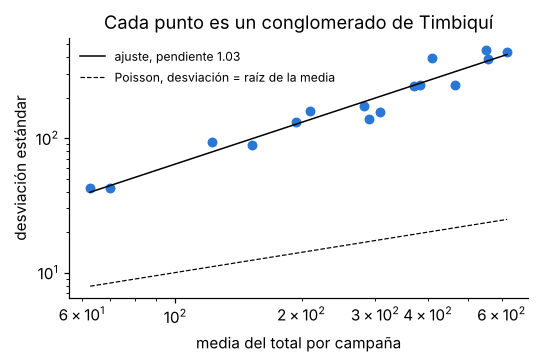

In [ ]:
disp_sitio = dev.groupby("cluster")["total"].agg(["mean", "std"])
pend, corte_log = np.polyfit(np.log(disp_sitio["mean"]), np.log(disp_sitio["std"]), 1)
print("pendiente de log(desviación) contra log(media)", round(pend, 2),
      " correlación", round(np.corrcoef(np.log(disp_sitio["mean"]), np.log(disp_sitio["std"]))[0, 1], 2))

fig, ax = plt.subplots(figsize=(5, 3.4))
ax.scatter(disp_sitio["mean"], disp_sitio["std"], color=azul, s=30)
xs = np.array([disp_sitio["mean"].min(), disp_sitio["mean"].max()])
ax.plot(xs, np.exp(corte_log) * xs ** pend, "k-", lw=1, label=f"ajuste, pendiente {pend:.2f}")
ax.plot(xs, np.sqrt(xs), "k--", lw=0.8, label="Poisson, desviación = raíz de la media")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("media del total por campaña")
ax.set_ylabel("desviación estándar")
ax.set_title("Cada punto es un conglomerado de Timbiquí")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

La pendiente es 1.03, con correlación 0.97, así que la desviación crece en proporción a la media. Con ruido de Poisson la pendiente sería 0.5 (línea punteada), y la desviación observada es entre 5 y 20 veces mayor que esa. Por eso describimos los datos con y. En la sección 4 el error del modelo se mide con el logaritmo natural, que es lo mismo en otra unidad (un factor 2 es 0.30 en log10 y 0.69 en ln).

# 3. Lo que cuentan los datos

## 3.1 Todo el estudio, Timbiquí o solo Cheté

El plan pedía decidir con qué datos trabajar. Para eso nos preguntamos cuántas expediciones hubo, si fueron en las mismas fechas, cómo cambian las capturas según la población y si las variables pesan lo mismo en cada región. Para medir cuánto pesa una característica reemplazamos el $y_i$ de cada campaña por el promedio de su grupo, $\bar y_{g(i)}$ (su conglomerado, su ronda o su mes), y medimos qué fracción de la variación desaparece:

$$R^2 = 1-\frac{\sum_i \left(y_i-\bar y_{g(i)}\right)^2}{\sum_i \left(y_i-\bar y\right)^2}.$$

Reemplazar cada valor por el promedio de su grupo equivale a una regresión lineal con una variable indicadora por grupo, así que este es el R² usual de esa regresión. Un ejemplo con cuatro campañas: y = 2.0 y 2.2 en el sitio A, y 1.0 y 1.2 en el sitio B. El promedio general es 1.6 y la variación total es 0.16 + 0.36 + 0.36 + 0.16 = 1.04. Con el promedio de cada sitio (2.1 y 1.1) sobra 4 × 0.01 = 0.04, así que R² = 1 − 0.04/1.04 = 0.96: saber el sitio explica el 96% de la variación. Una característica con muchos grupos explica algo aunque no tenga relación con la tasa, porque cada promedio se ajusta a pocas campañas. Por eso en la sección 3.3 comparamos cada R² con el que sale al barajar las etiquetas, que es una prueba de permutaciones.

In [ ]:
def r2(y, y_pred):
    return 1 - np.sum((y - y_pred) ** 2) / np.sum((y - y.mean()) ** 2)

def r2_grupo(datos, col, y="ltasa"):
    return r2(datos[y], datos.groupby(col, observed=True)[y].transform("mean"))

especies = ["albimanus", "neivai", "apicimacula"]
explora_todo = camp_todo[camp_todo["inicio"] < corte]
resumen_mun = explora_todo.groupby("municipio").agg(
    conglomerados=("cluster", "nunique"),
    campanas=("cluster", "size"),
    rondas=("ronda", "nunique"),
    tasa_mediana=("tasa", "median"),
)
comp_mun = explora_todo.groupby("municipio")[especies].sum()
resumen_mun["frac_albimanus"] = comp_mun["albimanus"] / comp_mun.sum(axis=1)
for col in ["cluster", "ronda"]:
    resumen_mun["R2 " + col] = [r2_grupo(explora_todo[explora_todo["municipio"] == m], col) for m in resumen_mun.index]
print(resumen_mun.round(2))
rondas_mun = explora_todo.groupby("municipio")["ronda"].apply(set)
print("rondas compartidas por los tres municipios", len(set.intersection(*rondas_mun.values)))

               conglomerados  campanas  rondas  tasa_mediana  frac_albimanus  \
municipio                                                                      
Guapi                     20       382      20         33.88            0.04   
Santa Bárbara              4        76      20         91.38            0.20   
Timbiquí                  16       301      19         72.00            0.22   

               R2 cluster  R2 ronda  
municipio                            
Guapi                0.42      0.11  
Santa Bárbara        0.15      0.38  
Timbiquí             0.44      0.13  
rondas compartidas por los tres municipios 19


Los tres municipios se visitaron en las mismas 19 rondas (Guapi y Santa Bárbara tienen una más), así que sus diferencias no vienen de haberlos muestreado en meses distintos. En los tres domina An. neivai, pero An. albimanus es el 22% de lo capturado en Timbiquí, el 20% en Santa Bárbara y apenas el 4% en Guapi. La tasa mediana va de 34 mosquitos por noche en Guapi a 91 en Santa Bárbara; Timbiquí tiene 72.

Las variables no pesan igual en las tres regiones. En Guapi y en Timbiquí el conglomerado explica más del 40% de la variación y la ronda poco, es decir, importa dónde se captura. En Santa Bárbara es al revés (ronda 38%, conglomerado 15%), aunque con solo 4 conglomerados ese resultado es frágil.

Con esto decidimos. Usar todo el estudio mezcla municipios donde las variables no pesan igual. Guapi se parece a Timbiquí en lo que pesa, pero casi no tiene An. albimanus, que es la especie de Cheté. Cheté solo son dos puntos, muy pocos para aprender una regla. Timbiquí es el municipio de Cheté y tiene 16 conglomerados, 4 de ellos de An. albimanus, así que trabajamos con Timbiquí. En la sección 4 comprobamos con la validación de 2022 que las otras opciones no predicen mejor a Cheté.

## 3.2 Timbiquí. Especie, sitios y personas

Dentro de Timbiquí la composición de especies cambia mucho de un conglomerado a otro. Clasificamos cada conglomerado por la fracción de An. neivai que ha capturado: menos de 0.4 es un sitio de albimanus, entre 0.4 y 0.8 un sitio mixto y más de 0.8 un sitio de neivai. Los cortes caen en dos huecos de la distribución, porque ningún conglomerado tiene una fracción entre 0.04 y 0.43 ni entre 0.76 y 0.91. Cualquier corte dentro de esos huecos da los mismos grupos.

                    localidad  frac_neivai  ltasa   segmento
cluster                                                     
Coteje1                Coteje         0.00   2.13  albimanus
Coteje2                Coteje         0.01   1.29  albimanus
Chete1                  Cheté         0.01   1.83  albimanus
Chete2                  Cheté         0.04   1.24  albimanus
Charco              El Charco         0.43   1.60      mixto
Velasquez           Velásquez         0.76   1.49      mixto
SMiguel2   San Miguel del Río         0.91   1.67     neivai
BrazoC            Brazo Corto         0.91   2.01     neivai
SMiguel1   San Miguel del Río         0.96   1.90     neivai
Mataco                 Mataco         0.97   2.21     neivai
Esperanza     Nueva Esperanza         0.99   1.99     neivai
Saija3           Puerto Saija         0.99   1.89     neivai
Saija2           Puerto Saija         1.00   1.70     neivai
Saija1           Puerto Saija         1.00   1.94     neivai
CPueblo1     Calle del P

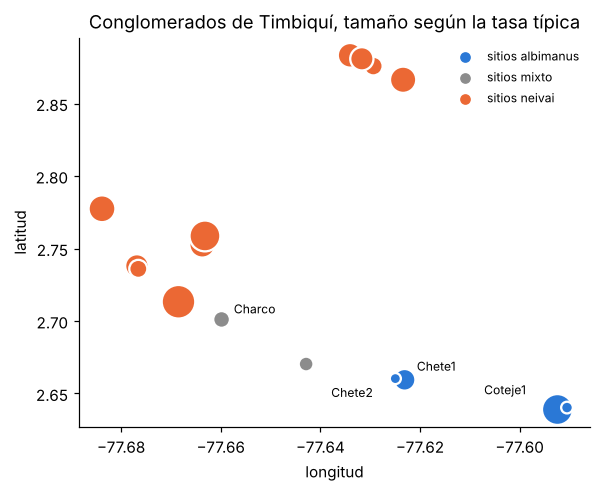

In [ ]:
sitios = dev.groupby("cluster").agg(
    localidad=("localidad", "first"),
    lat=("lat", "first"),
    lon=("lon", "first"),
    neivai=("neivai", "sum"),
    total=("total", "sum"),
    ltasa=("ltasa", "mean"),
)
sitios["frac_neivai"] = sitios["neivai"] / sitios["total"]
sitios["segmento"] = pd.cut(sitios["frac_neivai"], [0, 0.4, 0.8, 1], labels=["albimanus", "mixto", "neivai"], include_lowest=True).astype(str)
dev["segmento"] = dev["cluster"].map(sitios["segmento"])
print(sitios.sort_values("frac_neivai")[["localidad", "frac_neivai", "ltasa", "segmento"]].round(2))

color_segmento = {"albimanus": azul, "mixto": gris, "neivai": naranja}
fig, ax = plt.subplots(figsize=(6, 4.6))
ax.scatter(sitios["lon"], sitios["lat"], c=sitios["segmento"].map(color_segmento),
           s=30 * 10 ** (sitios["ltasa"] - 1), edgecolor="white", linewidth=1.5)
for nombre, d in {"Chete1": (8, 6), "Chete2": (-42, -12), "Coteje1": (-48, 10), "Charco": (8, 4)}.items():
    ax.annotate(nombre, (sitios.loc[nombre, "lon"], sitios.loc[nombre, "lat"]), xytext=d, textcoords="offset points", fontsize=8)
for s, col in color_segmento.items():
    ax.scatter([], [], color=col, label="sitios " + s)
ax.legend(frameon=False, fontsize=8)
ax.set_xlabel("longitud")
ax.set_ylabel("latitud")
ax.set_title("Conglomerados de Timbiquí, tamaño según la tasa típica")
plt.show()

Hay 4 sitios de albimanus (Chete 1, Chete 2, Coteje 1 y Coteje 2), 2 mixtos (El Charco y Velásquez) y 10 de neivai. Cheté y Coteje quedan juntos al sureste. Cheté no representa al municipio, porque es uno de los pocos lugares donde casi todo es An. albimanus.

El plan también preguntaba si importa la persona. La tabla trae recordedBy (quién registró) e identifiedBy (quién identificó la especie). La descripción del estudio no da nombres por captura, así que no sabemos si recordedBy es quien atrapó cada mosquito. Miramos cuándo aparece cada combinación de nombres. Si el cambio de identificadora afectara la clasificación, la fracción de neivai de cada conglomerado saltaría en la fecha del cambio (octubre de 2021). Comparamos ese salto con el que sale al cortar la serie en cualquier otra ronda.

In [ ]:
print(dev.groupby("periodo")["inicio"].agg(["min", "max", "size"]))

dev["frac_neivai_campana"] = dev["neivai"] / dev["total"]
def salto(datos, fecha):
    antes = datos[datos["inicio"] < fecha].groupby("cluster")["frac_neivai_campana"].mean()
    despues = datos[datos["inicio"] >= fecha].groupby("cluster")["frac_neivai_campana"].mean()
    return (despues - antes).dropna().mean()

saltos = pd.Series({str(r): salto(dev, r.to_timestamp()) for r in sorted(dev["ronda"].unique())[2:-2]})
s_cambio = saltos["2021-10"]
print("salto en la fracción de neivai al cambiar quien identifica", round(s_cambio, 3))
print("fracción de cortes con un salto igual o mayor", round(np.mean(saltos.abs() >= abs(s_cambio)), 2),
      " de", len(saltos), "cortes; saltos entre", round(saltos.min(), 3), "y", round(saltos.max(), 3))

                                          min        max  size
periodo                                                       
Diana / Jennifer y Karent          2021-10-05 2022-01-19    63
Diana / Karent y Edward            2021-01-20 2021-09-03    94
Diana y Edward / Jennifer y Karent 2022-02-02 2022-12-06   144
salto en la fracción de neivai al cambiar quien identifica 0.019
fracción de cortes con un salto igual o mayor 0.73  de 15 cortes; saltos entre 0.01 y 0.081


En Timbiquí recordedBy siempre incluye a Diana Marcela Lucumí, y desde comienzos de 2022 aparece junto a Edward Vargas. identifiedBy cambia una sola vez, en octubre de 2021, de Karent Cotazo y Edward Vargas a Jennifer Ballesteros y Karent Cotazo. Las tres combinaciones ocupan tres períodos seguidos que no se mezclan: 94 campañas de enero a septiembre de 2021, 63 de octubre de 2021 a enero de 2022 y 144 de febrero a diciembre de 2022. Cualquier diferencia entre personas queda confundida con el paso del tiempo (año, estación y fase del estudio), así que con esta tabla no se puede separar el efecto de quién registra.

El cambio de quién identifica sí se puede revisar. Cuando cambia la identificadora, la fracción de neivai sube 0.02, y 11 de los 15 cortes posibles (el 73%, incluido ese) dan un salto igual o mayor. Todos los saltos son positivos, entre 0.01 y 0.08, lo que indica que la fracción de neivai sube poco a poco durante el estudio y no de golpe con el cambio. No encontramos evidencia de un sesgo de identificación.

Ahora miramos la distribución de y según cada atributo que pedía el plan, todas en una misma figura. Cada campaña es un punto y la raya azul es la mediana de su grupo. Si un atributo segmenta los datos, sus grupos quedan separados; si se solapan, ese atributo dice poco. En la sección 3.3 lo medimos con el R².

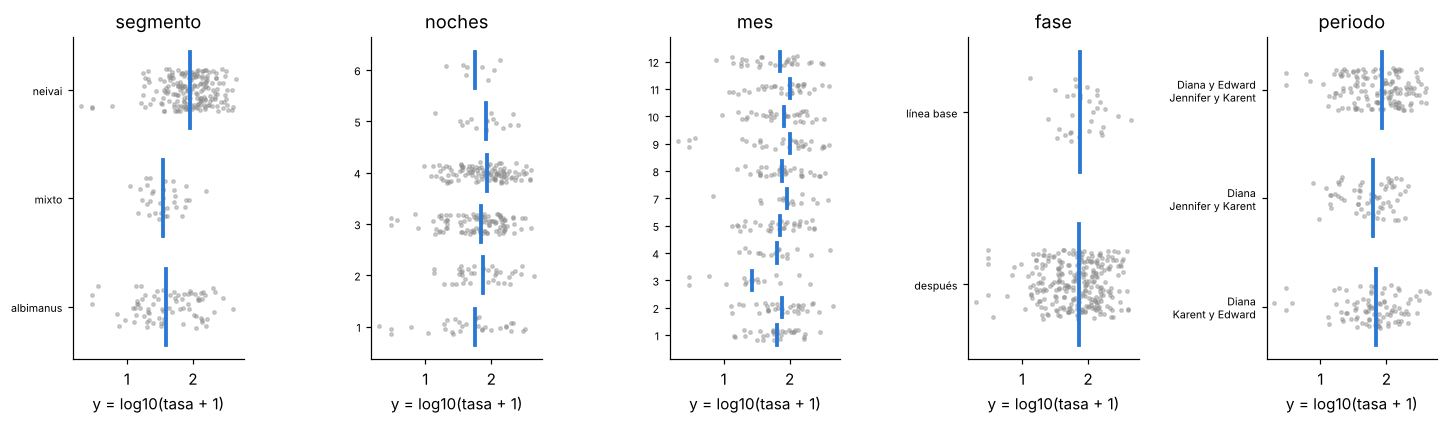

In [ ]:
dev["fase"] = np.where(dev["linea_base"], "línea base", "después")
atributos = ["segmento", "noches", "mes", "fase", "periodo"]
fig, axes = plt.subplots(1, len(atributos), figsize=(16, 3.8), sharex=True, gridspec_kw={"wspace": 0.75})
for ax, a in zip(axes, atributos):
    if a == "periodo":
        grupos = sorted(dev[a].unique(), key=lambda g: dev.loc[dev[a] == g, "inicio"].min())
    else:
        grupos = sorted(dev[a].unique())
    for k, g in enumerate(grupos):
        v = dev.loc[dev[a] == g, "ltasa"].values
        ax.scatter(v, k + rng.uniform(-0.2, 0.2, len(v)), s=5, color=gris, alpha=0.4)
        ax.plot([np.median(v)] * 2, [k - 0.35, k + 0.35], color=azul, lw=2.5)
    ax.set_yticks(range(len(grupos)))
    ax.set_yticklabels([str(g).replace(" / ", "\n") for g in grupos], fontsize=7)
    ax.set_title(a)
    ax.set_xlabel("y = log10(tasa + 1)")
plt.show()

El segmento de especie es el atributo cuyos grupos se separan más. Los sitios de neivai tienen una mediana de y cercana a 2 y los de albimanus y mixtos de unos 1.6. Los de albimanus están muy dispersos porque juntan los pares alto y bajo de Cheté y de Coteje (Chete 1 y Coteje 1 arriba, Chete 2 y Coteje 2 abajo). Las medianas por noches, mes, fase y período quedan casi todas entre 1.75 y 1.95, con los puntos encimados. La excepción es marzo, más bajo, por la ronda atípica de marzo de 2022. Que las noches no separen es lo esperado si dividir por el esfuerzo funciona, aunque no lo prueba. Que la línea base y el resto coincidan no dice nada sobre la intervención: la línea base solo cubre enero y febrero de 2021, y en Timbiquí se pueden compensar brazos cuyos efectos van en direcciones contrarias.

## 3.3 Qué pesa más

El mapa de calor muestra la tasa de cada conglomerado en cada ronda. Las bandas horizontales son sitios que siempre capturan mucho o poco, y las columnas claras son rondas bajas para todos a la vez, como septiembre de 2021 y marzo de 2022.

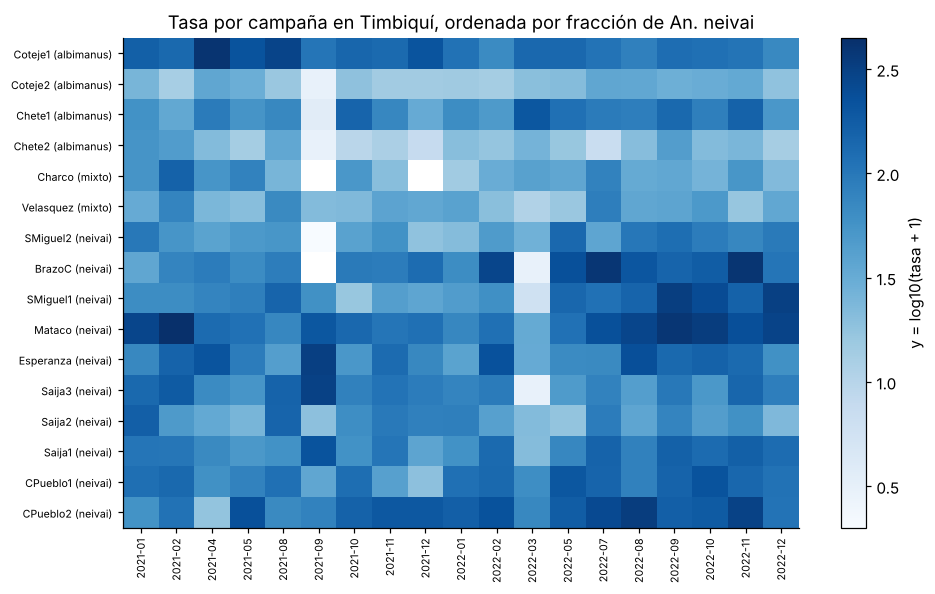

In [ ]:
orden = sitios.sort_values("frac_neivai").index
mapa = dev.pivot_table(index="cluster", columns="ronda", values="ltasa").loc[orden]
fig, ax = plt.subplots(figsize=(9, 5.5))
im = ax.imshow(mapa.values, aspect="auto", cmap="Blues")
ax.set_yticks(range(len(orden)))
ax.set_yticklabels([f"{c} ({sitios.loc[c, 'segmento']})" for c in orden], fontsize=7)
ax.set_xticks(range(len(mapa.columns)))
ax.set_xticklabels([str(r) for r in mapa.columns], rotation=90, fontsize=7)
plt.colorbar(im, label="y = log10(tasa + 1)")
ax.set_title("Tasa por campaña en Timbiquí, ordenada por fracción de An. neivai")
plt.tight_layout()
plt.show()

Para cada atributo calculamos el R² de la sección 3.1 y el R² promedio que sale al barajar sus valores entre campañas 200 veces. Al final juntamos conglomerado y ronda en una regresión con variables indicadoras, resuelta por mínimos cuadrados.

           grupos     R2  R2 por azar      p
cluster      16.0  0.442        0.050  0.000
localidad    10.0  0.233        0.030  0.000
segmento      3.0  0.155        0.007  0.000
ronda        19.0  0.130        0.058  0.000
mes          11.0  0.071        0.034  0.030
noches        6.0  0.034        0.016  0.075
fase          2.0  0.006        0.003  0.150
periodo       3.0  0.013        0.007  0.165
conglomerado + ronda 0.573  parámetros 34


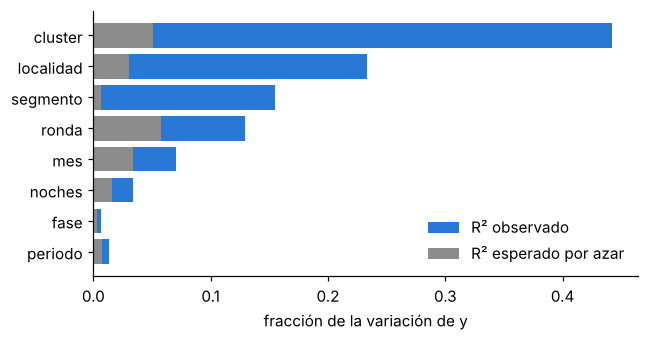

In [ ]:
caracteristicas = ["cluster", "localidad", "segmento", "ronda", "mes", "noches", "fase", "periodo"]
filas = {}
for c in caracteristicas:
    azar = []
    for b in range(200):
        barajado = dev.copy()
        barajado[c] = rng.permutation(barajado[c].values)
        azar.append(r2_grupo(barajado, c))
    filas[c] = {"grupos": dev[c].nunique(), "R2": r2_grupo(dev, c), "R2 por azar": np.mean(azar), "p": np.mean(np.array(azar) >= r2_grupo(dev, c))}
pesos = pd.DataFrame(filas).T

X_dummies = pd.get_dummies(dev[["cluster", "ronda"]].astype(str), drop_first=True).astype(float)
X_dummies.insert(0, "uno", 1.0)
theta_dummies, *_ = np.linalg.lstsq(X_dummies.values, dev["ltasa"].values, rcond=None)
print(pesos.round(3))
print("conglomerado + ronda", round(r2(dev["ltasa"].values, X_dummies.values @ theta_dummies), 3), " parámetros", X_dummies.shape[1])

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.barh(pesos.index, pesos["R2"], color=azul, label="R² observado")
ax.barh(pesos.index, pesos["R2 por azar"], color=gris, label="R² esperado por azar")
ax.invert_yaxis()
ax.set_xlabel("fracción de la variación de y")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

El sitio es lo que más pesa. El conglomerado explica el 44% de la variación de y (5% por azar), la localidad el 23% (3%), el segmento de especie el 16% (1%), la ronda el 13% (6%) y el mes el 7% (3%). Las noches (3%), la fase (1%) y el período de las personas (1%) no se distinguen del azar (p entre 0.08 y 0.17). Con conglomerado y ronda juntos llegamos al 57%, un valor algo inflado porque son 34 parámetros para 301 campañas. El resto es variación de una campaña a otra que estas características no capturan. Podría venir de cosas que no están en la tabla, como el clima de esas noches, el recolector o la vivienda.

La localidad explica la mitad que el conglomerado, así que dos conglomerados de la misma localidad pueden ser muy distintos, como pasa en Cheté (sección 3.4). Para predecir importa primero dónde se captura y después cuándo, y en ese orden construimos las características del modelo en la sección 4.

Como el conglomerado es lo que más pesa, describimos cada uno con unos pocos números: su nivel (promedio de y), su variabilidad entre visitas (desviación estándar de y), su tendencia (pendiente de y contra el tiempo, por año), su fracción de neivai y su ubicación. Con eso miramos cómo se parecen entre sí. El plan preguntaba si el PCA es una buena alternativa para estos datos. Para calcularlo estandarizamos los atributos, porque tienen unidades distintas, calculamos la matriz de covarianza y la diagonalizamos. Con 16 conglomerados, una correlación tiene que pasar de unos 0.50 en valor absoluto para ser distinta de cero al 5% (con $t = r\sqrt{n-2}/\sqrt{1-r^2}$ y 14 grados de libertad).

              nivel  variabilidad  tendencia  frac_neivai   lat   lon
nivel          1.00          0.11       0.21         0.49  0.35 -0.32
variabilidad   0.11          1.00       0.55         0.31  0.23 -0.57
tendencia      0.21          0.55       1.00         0.26 -0.06 -0.53
frac_neivai    0.49          0.31       0.26         1.00  0.76 -0.65
lat            0.35          0.23      -0.06         0.76  1.00 -0.18
lon           -0.32         -0.57      -0.53        -0.65 -0.18  1.00
fracción de la varianza explicada [0.482 0.239 0.128 0.081 0.061 0.008]
               PC1   PC2
nivel         0.34  0.28
variabilidad  0.39 -0.39
tendencia     0.35 -0.54
frac_neivai   0.51  0.33
lat           0.35  0.56
lon          -0.48  0.24


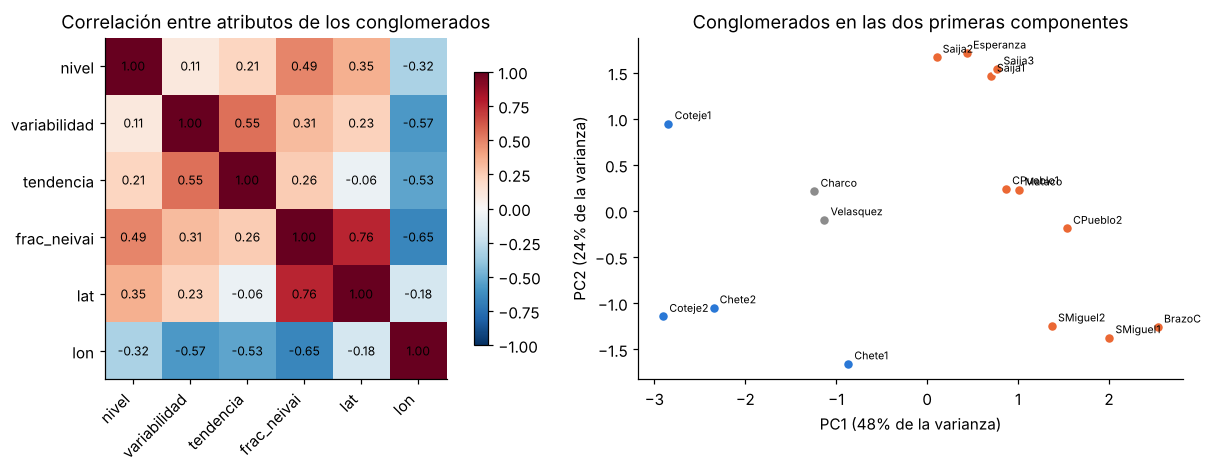

In [ ]:
def pendiente_anual(d):
    t = (d["inicio"] - d["inicio"].min()).dt.days / 365.25
    return np.polyfit(t, d["ltasa"], 1)[0]

perfil = pd.DataFrame({
    "nivel": dev.groupby("cluster")["ltasa"].mean(),
    "variabilidad": dev.groupby("cluster")["ltasa"].std(),
    "tendencia": dev.groupby("cluster").apply(pendiente_anual, include_groups=False),
    "frac_neivai": sitios["frac_neivai"],
    "lat": sitios["lat"],
    "lon": sitios["lon"],
})
Z = ((perfil - perfil.mean()) / perfil.std()).values
valores, vectores = np.linalg.eig(np.cov(Z.T))
valores, vectores = valores.real, vectores.real   # la matriz es simétrica, la parte imaginaria es cero
orden_pc = np.argsort(valores)[::-1]
valores, vectores = valores[orden_pc], vectores[:, orden_pc]
componentes = Z @ vectores
print(perfil.corr().round(2))
print("fracción de la varianza explicada", (valores / valores.sum()).round(3))
print(pd.DataFrame(vectores[:, :2], index=perfil.columns, columns=["PC1", "PC2"]).round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
im = axes[0].imshow(perfil.corr().values, cmap="RdBu_r", vmin=-1, vmax=1)
axes[0].set_xticks(range(6))
axes[0].set_xticklabels(perfil.columns, rotation=45, ha="right")
axes[0].set_yticks(range(6))
axes[0].set_yticklabels(perfil.columns)
for i in range(6):
    for j in range(6):
        axes[0].text(j, i, f"{perfil.corr().values[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, ax=axes[0], shrink=0.8)
axes[0].set_title("Correlación entre atributos de los conglomerados")
for c, (p1, p2) in zip(perfil.index, componentes[:, :2]):
    axes[1].scatter(p1, p2, color=color_segmento[sitios.loc[c, "segmento"]], s=50, edgecolor="white", linewidth=1.5)
    axes[1].annotate(c, (p1, p2), xytext=(4, 3), textcoords="offset points", fontsize=7)
axes[1].set_xlabel(f"PC1 ({valores[0] / valores.sum():.0%} de la varianza)")
axes[1].set_ylabel(f"PC2 ({valores[1] / valores.sum():.0%} de la varianza)")
axes[1].set_title("Conglomerados en las dos primeras componentes")
plt.tight_layout()
plt.show()

En la matriz de correlación la fracción de neivai va con la latitud (0.76) y en contra de la longitud (−0.65): los sitios del norte y del oeste son de neivai, y los del sureste, Cheté y Coteje, de albimanus. La variabilidad y la tendencia van juntas (0.55), y las dos bajan hacia el este (−0.57 y −0.53). Esas cinco correlaciones pasan el umbral de 0.50. La de nivel con fracción de neivai (0.49) queda justo en el límite.

La primera componente explica el 48% de la varianza y recoge ese gradiente de geografía y especie; sus pesos más grandes son la fracción de neivai (0.51) y la longitud (−0.48). A la izquierda quedan Coteje 1, Coteje 2 y Chete 2, luego los dos mixtos y Chete 1, y a la derecha los diez de neivai. Reaparece la segmentación de la sección 3.2, en parte porque la fracción de neivai es uno de los atributos. La segunda componente (24%) separa los sitios con más tendencia y variabilidad, abajo Chete 1, San Miguel y Brazo Corto, de los sitios estables del norte, arriba Puerto Saija y Nueva Esperanza.

Respondiendo al plan, el PCA no es una buena alternativa para el modelo. Con 16 conglomerados no hay suficientes sitios para reemplazar atributos por componentes. Además, lo que resume la primera componente, el nivel y la especie de cada sitio, ya entra al modelo por el historial de cada conglomerado y su fracción de neivai. Lo que sí muestra es que Cheté está en un extremo del municipio, así que una regla aprendida con todo Timbiquí lo va a acercar al promedio (lo medimos en la sección 4).

Falta ver si cada campaña se puede tratar como independiente. Si lo fuera, la campaña anterior de un conglomerado no diría nada de la siguiente. Medimos la correlación entre cada campaña y la anterior del mismo conglomerado. Hacemos lo mismo con la anomalía, $a_i = y_i - \bar y_{c(i)}$, que es cuánto se aleja cada campaña del promedio de su conglomerado. Para la anomalía usamos un nulo que baraja 1000 veces el orden de las campañas dentro de cada conglomerado.

correlación con la campaña anterior 0.48
con anomalías 0.07  por azar -0.06  p = 0.012


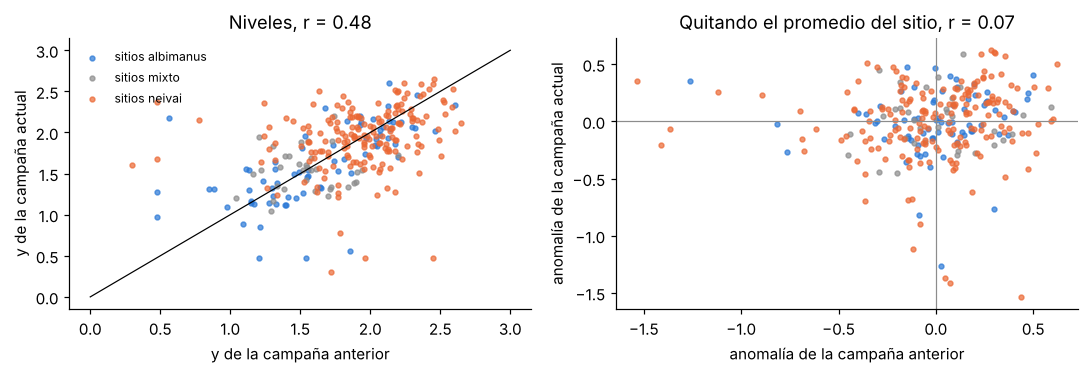

In [ ]:
dev = dev.sort_values(["cluster", "inicio"])
dev["anomalia"] = dev["ltasa"] - dev.groupby("cluster")["ltasa"].transform("mean")
dev["anterior"] = dev.groupby("cluster")["ltasa"].shift(1)
dev["anomalia_anterior"] = dev.groupby("cluster")["anomalia"].shift(1)
pares = dev.dropna(subset=["anterior"])
r_nivel = np.corrcoef(pares["anterior"], pares["ltasa"])[0, 1]
r_anom = np.corrcoef(pares["anomalia_anterior"], pares["anomalia"])[0, 1]

nulos_anom = []
for b in range(1000):
    tmp = dev.copy()
    tmp["anomalia"] = tmp.groupby("cluster")["anomalia"].transform(lambda s: rng.permutation(s.values))
    tmp["anomalia_anterior"] = tmp.groupby("cluster")["anomalia"].shift(1)
    p = tmp.dropna(subset=["anomalia_anterior"])
    nulos_anom.append(np.corrcoef(p["anomalia_anterior"], p["anomalia"])[0, 1])
nulos_anom = np.array(nulos_anom)
print("correlación con la campaña anterior", round(r_nivel, 2))
print("con anomalías", round(r_anom, 2), " por azar", round(nulos_anom.mean(), 2), " p =", np.mean(nulos_anom >= r_anom))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for seg, c in color_segmento.items():
    q = pares[pares["segmento"] == seg]
    axes[0].scatter(q["anterior"], q["ltasa"], s=10, color=c, alpha=0.7, label="sitios " + seg)
    axes[1].scatter(q["anomalia_anterior"], q["anomalia"], s=10, color=c, alpha=0.7)
axes[0].plot([0, 3], [0, 3], "k-", lw=0.8)
axes[0].set_xlabel("y de la campaña anterior")
axes[0].set_ylabel("y de la campaña actual")
axes[0].set_title(f"Niveles, r = {r_nivel:.2f}")
axes[0].legend(frameon=False, fontsize=8)
axes[1].axhline(0, color=gris, lw=0.8)
axes[1].axvline(0, color=gris, lw=0.8)
axes[1].set_xlabel("anomalía de la campaña anterior")
axes[1].set_ylabel("anomalía de la campaña actual")
axes[1].set_title(f"Quitando el promedio del sitio, r = {r_anom:.2f}")
plt.tight_layout()
plt.show()

Las campañas no son independientes. La correlación entre una campaña y la anterior del mismo conglomerado es 0.48, y casi toda se debe a que cada sitio tiene su propio nivel (en el panel izquierdo los puntos siguen la diagonal). Con las anomalías baja a 0.07. Es pequeña, pero mayor que la del nulo (−0.06, p = 0.012), así que queda algo de memoria de una visita a la siguiente. El nulo es negativo porque las anomalías de cada conglomerado suman cero, y eso por sí solo induce una correlación negativa entre campañas vecinas.

Esto afecta el resto del trabajo. El historial del conglomerado es la información más útil para predecir. No podemos repartir campañas al azar entre entrenamiento y prueba, porque el modelo aprendería del mismo sitio en meses futuros, así que la validación de la sección 4 respeta el tiempo. Y los intervalos bootstrap remuestrean bloques completos (conglomerados o rondas) y no campañas sueltas, porque las observaciones de un mismo bloque se parecen entre sí.

## 3.4 Cheté. Los dos puntos de captura

En la tabla Cheté aparece como dos conglomerados, Chete 1 y Chete 2, cada uno con una sola coordenada y sin avisos. No sabemos si un conglomerado es una casa, varias o un sector, ni si cada mes se muestrea la misma vivienda. Miramos el calendario de visitas, que incluye 2023 porque las fechas se conocen antes de cada campaña, y las capturas de cada visita antes de 2023.

visitas por punto {'Chete1': 22, 'Chete2': 22}
días que abarca una campaña, mediana según las noches {1: 1.0, 2: 8.0, 3: 13.0, 4: 17.0, 5: 28.0, 6: 28.0}
días de Chete2 después de Chete1 en la misma ronda, mediana 2.0
cluster  Chete1  Chete2  razón 1/2
ronda                             
2021-01    57.7    54.0        1.1
2021-02    33.4    43.7        0.8
2021-04    90.7    20.3        4.5
2021-05    53.3    12.5        4.3
2021-08    70.3    34.0        2.1
2021-09     2.7     2.0        1.3
2021-10   149.0     8.5       17.5
2021-11    72.0    11.2        6.4
2021-12    31.5     6.7        4.7
2022-01    63.8    19.3        3.3
2022-02    46.7    16.0        2.9
2022-03   199.0    25.0        8.0
2022-05   117.0    15.3        7.6
2022-07    92.0     6.0       15.3
2022-08    85.4    19.8        4.3
2022-09   133.3    42.8        3.1
2022-10    84.0    20.5        4.1
2022-11   156.5    23.5        6.7
2022-12    50.0    12.2        4.1
mediana por noche {'Chete1': 72.0, 'Chete2': 19

Chete1  factor por visita 1.057  p = 0.1258


Chete2  factor por visita 0.99  p = 0.7274


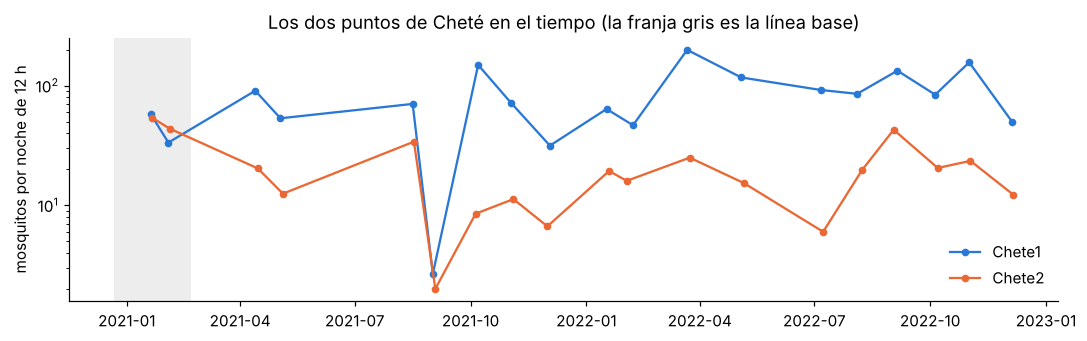

In [ ]:
chete_fechas = camp[camp["localidad"] == "Cheté"].copy()
chete_fechas["dias"] = (chete_fechas["fin"] - chete_fechas["inicio"]).dt.days + 1
inicios = chete_fechas.pivot_table(index="ronda", columns="cluster", values="inicio", aggfunc="min")
print("visitas por punto", chete_fechas.groupby("cluster").size().to_dict())
print("días que abarca una campaña, mediana según las noches", chete_fechas.groupby("noches")["dias"].median().to_dict())
print("días de Chete2 después de Chete1 en la misma ronda, mediana", (inicios["Chete2"] - inicios["Chete1"]).dt.days.median())

chete = dev[dev["localidad"] == "Cheté"].copy()
por_visita = chete.pivot_table(index="ronda", columns="cluster", values="tasa")
por_visita["razón 1/2"] = por_visita["Chete1"] / por_visita["Chete2"]
print(por_visita.round(1))
print("mediana por noche", chete.groupby("cluster")["tasa"].median().round(0).to_dict())
print("fracción de An. albimanus", (chete.groupby("cluster")["albimanus"].sum() / chete.groupby("cluster")["total"].sum()).round(3).to_dict())

# tendencia: recta de y contra el número de visita y prueba de permutaciones de la pendiente
for c in ["Chete1", "Chete2"]:
    s = chete[chete["cluster"] == c]
    obs = np.polyfit(s["visita"], s["ltasa"], 1)[0]
    nulos_p = np.array([np.polyfit(s["visita"], rng.permutation(s["ltasa"].values), 1)[0] for i in range(5000)])
    print(c, " factor por visita", round(10 ** obs, 3), " p =", np.mean(np.abs(nulos_p) >= abs(obs)))

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.axvspan(por_visita.index[0].to_timestamp() - pd.Timedelta(days=10), por_visita.index[1].to_timestamp() + pd.Timedelta(days=20), color=gris, alpha=0.15, lw=0)
for c, col in [("Chete1", azul), ("Chete2", naranja)]:
    s = chete[chete["cluster"] == c]
    ax.plot(s["inicio"], s["tasa"], "o-", color=col, label=c, ms=4, lw=1.5)
ax.set_yscale("log")
ax.set_ylabel("mosquitos por noche de 12 h")
ax.set_title("Los dos puntos de Cheté en el tiempo (la franja gris es la línea base)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

Cada punto fue visitado 22 veces entre enero de 2021 y marzo de 2023, casi siempre una vez al mes, y Chete 2 empieza en mediana unos 2 días después que Chete 1. Las noches de una campaña no son seguidas: una campaña de 4 noches se reparte en unos 17 días.

Chete 1 captura una mediana de 72 mosquitos por noche y Chete 2 de 19. En la línea base los dos puntos eran parecidos (58 contra 54 y 33 contra 44), y la separación aparece desde abril de 2021. Los dos son casi solo An. albimanus (98.5% y 96.2%), así que la diferencia no es de especie. En septiembre de 2021 caen los dos a la vez.

No detectamos tendencia. Ajustamos y = a + b · visita, y el factor por visita es $10^{b}$: 1.06 en Chete 1 (p = 0.13) y 0.99 en Chete 2 (p = 0.73). Con este ruido, una tendencia como la de Chete 1, que en 18 visitas sería un factor 2.7, no se distingue de cero. Como no hay una tendencia clara, el historial de cada punto sirve para predecir.

## 3.5 Volver a la estimación de Fermi

Comparamos cada supuesto con lo que muestran las campañas de Cheté antes de 2023. La tasa de Fermi era por trampa y hora, así que la medimos por recolector y hora, suponiendo los dos recolectores que indica la descripción. Le ponemos un intervalo bootstrap que remuestrea rondas completas, porque los dos puntos de un mismo mes no son independientes. Después llevamos cada ronda a 4 noches de 12 horas en los dos puntos, que son 2 × 2 × 12 × 4 = 192 horas de recolector, las mismas 192 horas nominales de nuestra Fermi.

         count  mean   std   min   25%   50%   75%   max
cluster                                                 
Chete1    19.0  3.48  2.04  0.11  2.15  3.00  4.35  8.29
Chete2    19.0  0.86  0.58  0.08  0.49  0.81  1.01  2.25
fracción de campañas con más de un mosquito por recolector y hora 0.61


mosquitos por recolector y hora 2.19 IC 95% [1.8 2.6]
rondas con los dos puntos 19  mediana 417  mínimo 19  máximo 896
rondas dentro del rango de Fermi 14
por debajo {'2021-09': 19}
por encima {'2021-10': 630, '2022-03': 896, '2022-09': 704, '2022-11': 720}


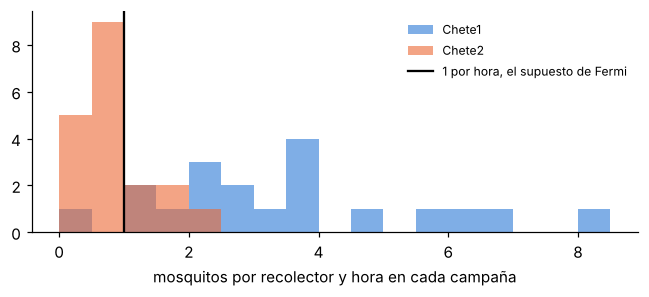

In [ ]:
chete["por_recolector_hora"] = chete["total"] / (2 * chete["horas"] * chete["noches"])
print(chete.groupby("cluster")["por_recolector_hora"].describe().round(2))
print("fracción de campañas con más de un mosquito por recolector y hora", round((chete["por_recolector_hora"] > 1).mean(), 2))

def tasa_media(d):
    return d["total"].sum() / (2 * d["horas"] * d["noches"]).sum()

rondas_chete = chete["ronda"].unique()
boot = []
for b in range(2000):
    elegidas = rng.choice(rondas_chete, len(rondas_chete))
    boot.append(tasa_media(pd.concat([chete[chete["ronda"] == r] for r in elegidas])))
print("mosquitos por recolector y hora", round(tasa_media(chete), 2), "IC 95%", np.quantile(boot, [0.025, 0.975]).round(2))

chete["total_4noches"] = chete["tasa"] * 4
por_ronda = chete.groupby("ronda")["total_4noches"].agg(["sum", "size"])
real4 = por_ronda.loc[por_ronda["size"] == 2, "sum"]
print("rondas con los dos puntos", len(real4), " mediana", round(real4.median()), " mínimo", round(real4.min()), " máximo", round(real4.max()))
print("rondas dentro del rango de Fermi", int(((real4 >= total_fermi(fermi_bajo)) & (real4 <= total_fermi(fermi_alto))).sum()))
print("por debajo", {str(r): round(v) for r, v in real4[real4 < total_fermi(fermi_bajo)].items()})
print("por encima", {str(r): round(v) for r, v in real4[real4 > total_fermi(fermi_alto)].items()})

fig, ax = plt.subplots(figsize=(6, 2.8))
for c, col in [("Chete1", azul), ("Chete2", naranja)]:
    ax.hist(chete.loc[chete["cluster"] == c, "por_recolector_hora"], bins=np.arange(0, 9, 0.5), color=col, alpha=0.6, label=c)
ax.axvline(1, color="k", lw=1.5, label="1 por hora, el supuesto de Fermi")
ax.set_xlabel("mosquitos por recolector y hora en cada campaña")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

En el 61% de las campañas se pasa de 1 mosquito por recolector y hora, con un máximo de 8.3. No hay un tope de uno por hora: se captura lo que llega, y el frasco por hora es solo la forma de empacar.

| Supuesto | Fermi | Lo que muestran los datos de Cheté | ¿Resistió? |
|---|---|---|---|
| Método | trampas | captura con atrayente humano | No, otro método |
| Personas | 8 | 2 recolectores por punto, 4 en Cheté | No, la mitad |
| Puntos de captura | 8 trampas en 4 escenarios | 2 puntos, con un recolector dentro y otro fuera rotando | No |
| Horas por noche | 6, en bloques con capturas de 15 minutos | 12, de 17:00 a 5:00 (14 en la línea base) | No |
| Esfuerzo por noche | 48 horas de trampa | 48 horas de recolector | Sí en horas nominales |
| Noches | 4 | entre 1 y 6, 3 o 4 en 29 de las 38 campañas | Sí, aunque varía |
| Mosquitos por trampa y hora | 1 (de 0.5 a 3) | 2.2 por recolector y hora (IC 95% de 1.8 a 2.6), mediana 3.0 en Chete 1 y 0.8 en Chete 2 | No, era el doble |
| Especie | no lo sabíamos | 98% An. albimanus | Información nueva |
| Cercanía al agua, dentro contra fuera | el factor más importante | no está en los datos publicados | No se puede probar |
| Temporada de lluvias | supuesto del escenario | la tabla no trae lluvia, y en Timbiquí el mes explica el 7% (3% por azar) | No se puede probar con esta tabla |

Si llevamos cada ronda a 4 noches de 12 horas, los dos puntos juntos suman una mediana de 417 mosquitos (entre 19 y 896). El rango de Fermi, de 96 a 576, contuvo 14 de las 19 rondas. Una quedó por debajo, septiembre de 2021 con 19, y cuatro por encima, entre 630 y 896 (octubre de 2021 y marzo, septiembre y noviembre de 2022). Como el esfuerzo coincidió, la diferencia viene de la tasa, y la Fermi revisada para Cheté es

$$N = 2\ \text{puntos}\times 2\ \text{recolectores}\times 12\ \text{h}\times 4\ \text{noches}\times 2.2 \approx 420.$$

La tasa sí era el supuesto que más pesaba, pero no es un número de la región sino de cada punto. Chete 1 tiene una tasa típica de 3 por recolector y hora y Chete 2 de 0.8. Entre los dos cubren casi todo el rango de 0.5 a 3 que pusimos por desconocimiento, así que para Cheté no sirve una sola cifra.

## 3.6 El hallazgo que ponemos a prueba. Chete 1 captura casi cuatro veces más que Chete 2

Chete 1 y Chete 2 están en la misma localidad y se visitaron en las mismas rondas. Para compararlos sin que influya el mes usamos la diferencia en cada ronda y su promedio:

$$d_r = y_{\text{Chete 1},\,r}-y_{\text{Chete 2},\,r},\qquad \text{razón típica} = 10^{\bar d}.$$

Si los dos puntos fueran iguales, que uno u otro saliera más alto en cada ronda sería cuestión de azar. La prueba de permutaciones baraja las etiquetas Chete 1 y Chete 2 dentro de cada ronda, lo que equivale a cambiar al azar el signo de cada $d_r$, y cuenta qué tan seguido sale un $\bar d$ tan grande como el observado. El intervalo sale de un bootstrap sobre las rondas.

In [ ]:
lat = np.radians(sitios.loc[["Chete1", "Chete2"], "lat"].values)
lon = np.radians(sitios.loc[["Chete1", "Chete2"], "lon"].values)
distancia = 6371000 * np.sqrt((lat[1] - lat[0]) ** 2 + (np.cos(lat.mean()) * (lon[1] - lon[0])) ** 2)
print("distancia entre Chete1 y Chete2 en metros", round(distancia))

def diferencias(datos, col="ltasa"):
    t = datos.pivot_table(index="ronda", columns="cluster", values=col, aggfunc="mean").dropna()
    return t["Chete1"] - t["Chete2"]

def prueba_signos(d, n=10000):
    observado = d.mean()
    nulos = np.array([np.mean(d.values * rng.choice([-1, 1], len(d))) for i in range(n)])
    return observado, np.mean(np.abs(nulos) >= abs(observado))

d = diferencias(chete)
obs, p = prueba_signos(d)
ic = np.quantile([np.mean(rng.choice(d.values, len(d))) for i in range(5000)], [0.025, 0.975])
print("rondas", len(d), " con Chete1 > Chete2", (d > 0).sum(), " d medio", round(obs, 3), " p =", p)
print("razón típica", round(10 ** obs, 2), "IC 95%", (10 ** ic).round(2))

distancia entre Chete1 y Chete2 en metros 227


rondas 19  con Chete1 > Chete2 18  d medio 0.582  p = 0.0
razón típica 3.82 IC 95% [2.69 5.39]


Para ver si el hallazgo depende de cómo hicimos el análisis, cambiamos una decisión a la vez y repetimos la prueba.

In [ ]:
chete_alb = chete.copy()
chete_alb["ltasa"] = np.log10(chete_alb["albimanus"] / chete_alb["esfuerzo"] + 1)
chete_total = chete.copy()
chete_total["ltasa"] = np.log10(chete_total["total"] + 1)
variantes = {
    "análisis base": chete,
    "total sin dividir por el esfuerzo": chete_total,
    "solo An. albimanus": chete_alb,
    "sin la línea base de 14 h": chete[chete["horas"] == 12],
    "solo campañas de 3 o más noches": chete[chete["noches"] >= 3],
}
filas = []
for nombre, datos in variantes.items():
    dd = diferencias(datos)
    o, pv = prueba_signos(dd, 5000)
    filas.append([nombre, len(dd), round(10 ** o, 2), pv])
print(pd.DataFrame(filas, columns=["decisión", "rondas", "razón típica", "p"]).to_string(index=False))

                         decisión  rondas  razón típica      p
                    análisis base      19          3.82 0.0002
total sin dividir por el esfuerzo      19          4.23 0.0000
               solo An. albimanus      19          3.97 0.0000
        sin la línea base de 14 h      17          4.53 0.0002
  solo campañas de 3 o más noches      14          4.42 0.0002


Por último, ¿es Cheté un caso raro? Para cada localidad con dos o más conglomerados calculamos la razón típica entre el más alto y el más bajo, usando todas las rondas, solo la línea base y solo lo posterior. Como es un ensayo de intervención y no sabemos qué brazo recibió cada conglomerado, la línea base, anterior a cualquier intervención, es la única forma de ver si la diferencia ya existía.

In [ ]:
filas = []
for loc, datos in dev.groupby("localidad"):
    if datos["cluster"].nunique() < 2:
        continue
    fila = [loc, datos["cluster"].nunique()]
    for sub in [datos, datos[datos["linea_base"]], datos[~datos["linea_base"]]]:
        t = sub.pivot_table(index="ronda", columns="cluster", values="ltasa").dropna()
        fila.append(round(10 ** (t.mean().max() - t.mean().min()), 2) if len(t) else np.nan)
    filas.append(fila)
print(pd.DataFrame(filas, columns=["localidad", "conglomerados", "razón, todas", "línea base", "después"]).to_string(index=False))

         localidad  conglomerados  razón, todas  línea base  después
  Calle del Pueblo              2          1.43        1.60     1.57
             Cheté              2          3.82        1.10     4.53
            Coteje              2          6.96        8.28     6.81
      Puerto Saija              3          1.73        1.75     1.82
San Miguel del Río              2          1.69        1.12     1.82


En 18 de 19 rondas Chete 1 capturó más que Chete 2, a 227 metros de distancia. La razón típica es 3.8 (IC 95% de 2.7 a 5.4) y ninguna de las 10000 permutaciones dio una diferencia tan grande (p < 0.0001). El hallazgo se mantiene con los cuatro cambios de análisis, con razones entre 4.0 y 4.5 y p de 0.0002 o menos.

Cheté no es el caso típico. En las cinco localidades de Timbiquí con dos o más conglomerados, la razón entre el más alto y el más bajo es de 1.4 a 1.7 en Calle del Pueblo, San Miguel del Río y Puerto Saija, 3.8 en Cheté y 7.0 en Coteje. Las dos razones altas son las de las localidades de albimanus, pero con dos localidades no podemos decir que la especie sea la causa.

La línea base cambia la lectura. En Cheté la razón era 1.1 en la línea base (2 rondas) y 4.5 después (17 rondas), mientras que en Coteje ya era 8.3 antes de intervenir. En Coteje la desigualdad ya existía y en Cheté apareció después. Con 2 rondas de línea base no podemos saber si la diferencia viene del sitio, de la vivienda muestreada o de que los dos puntos recibieron intervenciones distintas. Para planear da igual la causa: los dos puntos no se pueden promediar, y por eso el modelo predice cada uno por separado y luego los suma.

# 4. Antes de la próxima visita. El modelo

La sección va en este orden: qué se predice y cómo se mide el error (4.1), las características (4.2), la partición de los datos (4.3), los modelos y su comparación (4.4 a 4.7), cómo se comporta el modelo elegido (4.8 a 4.12), la evaluación en 2023 (4.13) y la predicción para Cheté (4.14).

## 4.1 Qué predecimos y cómo sabremos si funciona

El equipo pregunta cuántos mosquitos va a traer. Predecimos el total de mosquitos (las tres especies, solo hembras) de la próxima campaña de cada conglomerado, sabiendo de antemano cuántas noches va a durar. Para Cheté predecimos Chete 1 y Chete 2 por separado, porque en la sección 3.6 Chete 1 capturó unas 3.8 veces más que Chete 2, y sumamos los dos en 4 noches de 12 horas. De esa cifra dependen la sílica gel y las horas de laboratorio.

Los frascos no los predecimos. La descripción del estudio dice que se empaca indicando conglomerado, vivienda, sitio y hora. De ahí inferimos, aunque no está escrito, que hay un frasco por recolector y por hora, es decir 2 × 12 × 4 = 96 por conglomerado. Si es así, los frascos los fija el protocolo y no el conteo, y hay que confirmarlo con el equipo.

Consideramos buena una predicción si lo observado queda entre la mitad y el doble de lo predicho. Para cada campaña calculamos

$$\text{error\_log} = \ln\frac{\text{observado} + 1}{\text{predicho} + 1}$$

La métrica principal es la fracción de campañas dentro de un factor 2, es decir con |error_log| < ln 2 ≈ 0.69. El factor 2 sale de la consideracion del equipo de que comprar con un margen del doble es viable, y un error mayor deja insumos sin usar o se queda corto. También reportamos el error típico, exp(mediana de |error_log|), y el error relativo de cada modelo,

$$E = \frac{\sum_i \left|\text{observado}_i - \text{predicho}_i\right|}{\sum_i \text{observado}_i} \times 100\%,$$

que dice de cada 100 mosquitos capturados en cuántos se equivocó el modelo. Cada modelo tiene el suyo y el más bajo es el mejor. El +1 evita el logaritmo de cero. Medimos en logaritmo porque el ruido es multiplicativo (sección 2.3), y así predecir la mitad cuesta lo mismo que predecir el doble en cualquier sitio.

In [ ]:
rng = np.random.default_rng(2024)   # reinicio para que la sección 4 no dependa de cuánto azar usan las anteriores

def metricas(obs, pred):
    error_log = np.log((obs + 1) / (pred + 1))
    return {
        "dentro factor 2": np.mean(np.abs(error_log) < np.log(2)),
        "error típico (factor)": np.exp(np.median(np.abs(error_log))),
        "error relativo (%)": 100 * np.sum(np.abs(obs - pred)) / np.sum(obs),
    }

## 4.2 Qué sabemos antes de la visita

La tabla tiene 69 columnas y 31 tienen un solo valor (sección 2). De las demás, unas son información de laboratorio que solo existe después de capturar, como la especie, quién identificó o el propio conteo. Las otras dicen dónde y cuándo se capturó y con cuánto esfuerzo. Para predecir la próxima campaña solo sirve lo que se conoce antes de la visita y cambia de una campaña a otra, y eso deja el lugar, la fecha y el esfuerzo.

El esfuerzo (noches × horas / 12) no es una característica: lo fija el plan del viaje y multiplica la predicción (sección 4.4).

Para el lugar y la fecha nos guiamos por el R² de la sección 3.3. El conglomerado explica el 44% de la variación del logaritmo de la tasa, así que lo principal es describir el sitio. En vez de 15 variables indicadoras usamos su historial, que se calcula igual para cualquier sitio con visitas previas. La variable historico es el promedio de log10(tasa + 1) en todas las campañas anteriores del conglomerado, el mismo promedio de grupo del R² pero solo con el pasado. lag1 es el log10(tasa + 1) de la campaña anterior y recoge la pequeña memoria de una visita a la siguiente (sección 3.3). El segmento de especie explica el 16% y lo representamos con neiv_hist, la fracción de An. neivai capturada hasta esa campaña. La ronda explica el 13%, pero su valor solo se conoce después de capturar. Lo más parecido que se sabe antes es regional, el promedio de lag1 de todos los conglomerados en esa ronda. El mes explica el 7% y lo escribimos como sin_mes y cos_mes para que diciembre quede junto a enero. Las noches explican el 3% y ya entran por el esfuerzo. No usamos quién registra, porque va con el período y no con cada captura (sección 3.2), ni la línea base, que son solo 2 rondas.

Cada característica se calcula solo con campañas anteriores del mismo conglomerado, así que se puede calcular sobre toda la tabla sin que 2023 se filtre hacia atrás. La primera campaña de cada conglomerado se pierde porque no tiene pasado.

In [ ]:
def preparar(tabla):
    t = tabla.sort_values(["cluster", "inicio"]).copy()
    g = t.groupby("cluster")
    t["historico"] = g["ltasa"].transform(lambda s: s.shift(1).expanding().mean())
    t["lag1"] = g["ltasa"].shift(1)
    t["neiv_hist"] = g["neivai"].transform(lambda s: s.shift(1).cumsum()) / g["total"].transform(lambda s: s.shift(1).cumsum())
    t["regional"] = t.groupby("ronda")["lag1"].transform("mean")
    t["sin_mes"] = np.sin(2 * np.pi * t["mes"] / 12)
    t["cos_mes"] = np.cos(2 * np.pi * t["mes"] / 12)
    return t.dropna(subset=["lag1"]).copy()

candidatas = ["historico", "lag1", "neiv_hist", "regional", "sin_mes", "cos_mes"]
modelable = preparar(camp)
dev_m = modelable[modelable["inicio"] < corte].copy()
final_m = modelable[modelable["inicio"] >= corte].copy()
print(len(dev_m), "campañas para construir el modelo,", len(final_m), "reservadas")
print(dev_m.loc[dev_m["cluster"] == "Chete1", ["ronda", "total", "esfuerzo", "ltasa"] + candidatas].set_index("ronda").tail(3).round(2))

285 campañas para construir el modelo, 48 reservadas
         total  esfuerzo  ltasa  historico  lag1  neiv_hist  regional  \
ronda                                                                   
2022-10    336       4.0   1.93       1.80  2.13       0.01      2.03   
2022-11    626       4.0   2.20       1.81  1.93       0.01      1.96   
2022-12    200       4.0   1.71       1.83  2.20       0.01      2.00   

         sin_mes  cos_mes  
ronda                      
2022-10    -0.87     0.50  
2022-11    -0.50     0.87  
2022-12    -0.00     1.00  


Quedan 285 campañas para construir el modelo y 48 reservadas. La tabla muestra las tres últimas campañas de Chete 1 en 2022 con sus seis candidatas. En noviembre historico vale 1.81, es decir, las campañas anteriores promedian unos 10^1.81 − 1 ≈ 64 mosquitos por noche en media geométrica. lag1 vale 1.93, que es el ltasa de octubre.

Antes de elegir miramos la matriz de correlación entre las candidatas, porque dos columnas casi proporcionales vuelven inestable la ecuación normal.

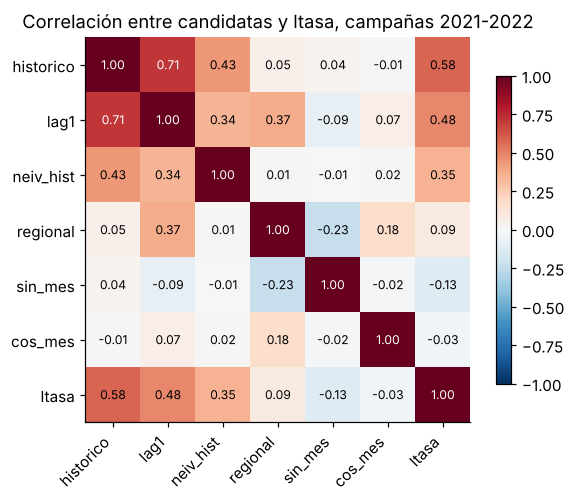

In [ ]:
corr_c = dev_m[candidatas + ["ltasa"]].corr()
fig, ax = plt.subplots(figsize=(5.6, 4.6))
im = ax.imshow(corr_c.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_c)))
ax.set_xticklabels(corr_c.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr_c)))
ax.set_yticklabels(corr_c.columns)
for i in range(len(corr_c)):
    for j in range(len(corr_c)):
        ax.text(j, i, f"{corr_c.values[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr_c.values[i, j]) > 0.6 else "black")
plt.colorbar(im, shrink=0.8)
ax.set_title("Correlación entre candidatas y ltasa, campañas 2021-2022")
plt.tight_layout()
plt.show()

historico y lag1 tienen correlación 0.71, porque la última campaña también entra en el promedio histórico. Es una colinealidad suave: no impide resolver el sistema, pero el peso se puede repartir entre las dos de forma inestable, y hay que tenerlo en cuenta al leer los coeficientes. Ninguna otra pareja de candidatas pasa de 0.43 en valor absoluto. Con ltasa, que es lo que se quiere predecir, las más correlacionadas son historico (0.58), lag1 (0.48) y neiv_hist (0.35). regional (0.09), sin_mes (−0.13) y cos_mes (−0.03) casi no se relacionan. Esto coincide con la sección 3.3, pero una correlación de a pares no dice cuánto aporta una variable cuando ya están las otras. Eso lo decide la selección de la sección 4.6.

## 4.3 Partición respetando el tiempo

Las campañas no se pueden barajar entre entrenamiento y prueba. Una campaña se correlaciona 0.48 con la anterior del mismo conglomerado (sección 3.3), así que una campaña de prueba tendría a sus vecinas en el tiempo dentro del entrenamiento y el error saldría optimista. Por eso partimos por tiempo. Las rondas de 2021 solo entrenan. Las 10 rondas de 2022 son la validación con origen móvil: para predecir cada ronda entrenamos solo con las anteriores, como pasa antes de cada viaje, y con esa validación comparamos modelos y elegimos variables. Las 3 rondas de 2023 son la prueba final y se predicen una sola vez con el modelo entrenado con 2021 y 2022.

En la figura cada fila es un ajuste. La ronda 2021-01 es la primera visita de los 16 conglomerados, así que solo aporta historial y nunca se predice.

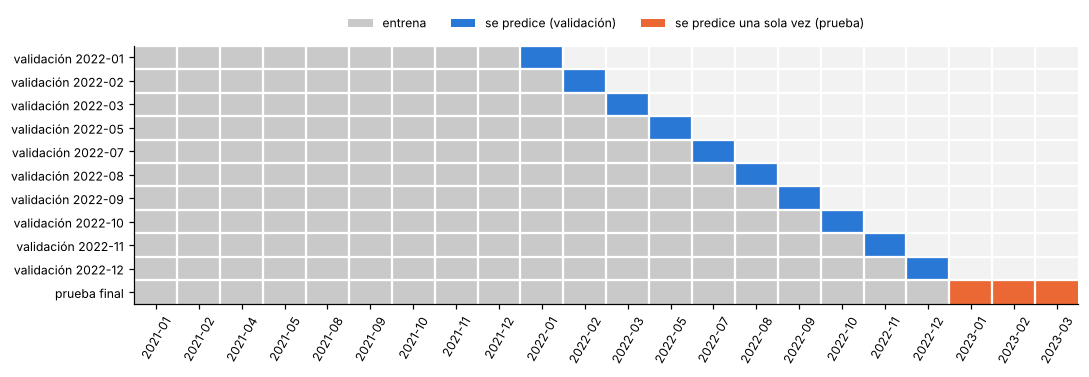

rondas de validación 10  rondas de prueba 3


In [ ]:
rondas_todas = sorted(camp["ronda"].unique())
rondas_val = sorted(dev_m.loc[dev_m["inicio"] >= "2022-01-01", "ronda"].unique())
rondas_prueba = sorted(final_m["ronda"].unique())

# 0 sin usar, 1 entrena, 2 se predice en validación, 3 prueba final
papel = np.zeros((len(rondas_val) + 1, len(rondas_todas)))
for i, r in enumerate(rondas_val):
    papel[i] = [1 if x < r else (2 if x == r else 0) for x in rondas_todas]
papel[-1] = [3 if x in rondas_prueba else 1 for x in rondas_todas]

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.imshow(papel, cmap=ListedColormap(["#f2f2f2", "#c9c9c9", azul, naranja]), vmin=0, vmax=3, aspect="auto")
ax.set_xticks(range(len(rondas_todas)))
ax.set_xticklabels([str(r) for r in rondas_todas], rotation=60, fontsize=8)
ax.set_yticks(range(len(papel)))
ax.set_yticklabels([f"validación {r}" for r in rondas_val] + ["prueba final"], fontsize=8)
ax.set_xticks(np.arange(len(rondas_todas)) - 0.5, minor=True)
ax.set_yticks(np.arange(len(papel)) - 0.5, minor=True)
ax.grid(which="minor", color="white", lw=1.5)
ax.tick_params(which="minor", length=0)
for color, nombre in [("#c9c9c9", "entrena"), (azul, "se predice (validación)"), (naranja, "se predice una sola vez (prueba)")]:
    ax.bar([0], [0], color=color, label=nombre)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.16), fontsize=8)
plt.tight_layout()
plt.show()
print("rondas de validación", len(rondas_val), " rondas de prueba", len(rondas_prueba))

## 4.4 Modelos considerados

Comparamos cinco modelos, con la misma validación y las mismas variables.

Los tres primeros loa utilizamos como referencias que cualquiera del equipo puede calcular en papel. La tasa típica de Timbiquí multiplica la tasa mediana de todas las campañas de entrenamiento por el esfuerzo, así que da una sola cifra para todos los sitios. La persistencia repite la tasa de la campaña anterior del conglomerado, (10^lag1 − 1) · esfuerzo. El promedio del sitio usa la media geométrica de sus campañas anteriores, (10^historico − 1) · esfuerzo.

El cuarto es una regresión sobre la tasa por noche con la ecuación normal θ = (XᵀX)⁻¹Xᵀy, resuelta con np.linalg.solve, y la tasa predicha se multiplica por el esfuerzo. Mínimos cuadrados es la máxima verosimilitud cuando el ruido es gaussiano y varianza constante. Nuestros datos no son así, son conteos, no pueden ser negativos y su desviación crece con la media como vimos antes. Una recta puede dar tasas negativas y en ese caso decimos que es cero

El quinto es una regresión de Poisson, que cambia el supuesto de ruido y deja igual el procedimiento. Si el conteo de una campaña sigue una distribución de Poisson de media

$$\mu = \text{esfuerzo}\cdot e^{\theta^T x},$$

la tasa por noche e^{θᵀx} siempre es positiva y el esfuerzo se multiplica, así que campañas de 1, 3 o 6 noches se comparan directamente. Maximizar la verosimilitud es minimizar la log-verosimilitud negativa por campaña,

$$J(\theta) = \frac{1}{m}\sum_{i=1}^{m}\left[\mu_i - y_i \ln \mu_i\right],$$

y como $∂μ_i/∂θ_j = μ_i x_j$, su gradiente es

$$\frac{\partial J}{\partial \theta_j} = \frac{1}{m}\sum_{i=1}^{m}\left(\mu_i - y_i\right)x_j^{(i)},$$

que tiene la misma forma que el de una regresión logística, predicción menos observación por la característica. Lo minimizamos con descenso del gradiente. Dividimos el gradiente por el promedio y para que el tamaño del paso no dependa de la escala de los conteos, lo que equivale a cambiar α. Las características se estandarizan con la media y la desviación del entrenamiento, así que cada θ_j mide el efecto de una desviación estándar.

La función validar recorre la partición de la sección 4.3 y da las predicciones de los cinco modelos a la vez.

In [ ]:
def escalas(datos, cols):
    desv = datos[cols].std().values
    return datos[cols].mean().values, np.where(desv == 0, 1, desv)   # una indicadora que no varía en el subconjunto

def matriz(datos, media, desv, cols):
    Z = (datos[cols].values - media) / desv
    return np.column_stack([np.ones(len(datos)), Z])

def ajustar_lineal(X, tasa):
    return np.linalg.solve(X.T @ X, X.T @ tasa)   # ecuación normal

def ajustar_poisson(X, y, esfuerzo, alpha=0.02, iteraciones=4000, historia=False):
    theta = np.zeros(X.shape[1])
    theta[0] = np.log(y.sum() / esfuerzo.sum())
    costes = []
    for i in range(iteraciones):
        mu = esfuerzo * np.exp(X @ theta)
        costes.append(np.mean(mu - y * np.log(mu)))
        grad = X.T @ (mu - y) / len(y)
        theta = theta - alpha * grad / y.mean()   # dividir por el promedio de y escala el paso a conteos de cientos
    return (theta, costes) if historia else theta

def predecir(theta, X, esfuerzo):
    return esfuerzo * np.exp(X @ theta)

def validar(datos, cols, rondas=None):
    filas = []
    for r in (rondas_val if rondas is None else rondas):
        entreno = datos[datos["ronda"] < r]
        prueba = datos[datos["ronda"] == r]
        if len(prueba) == 0:
            continue
        media, desv = escalas(entreno, cols)
        Xe, Xp = matriz(entreno, media, desv, cols), matriz(prueba, media, desv, cols)
        out = prueba[["cluster", "localidad", "ronda", "total", "esfuerzo"]].copy()
        out["tasa típica"] = entreno["tasa"].median() * prueba["esfuerzo"]
        out["persistencia"] = (10 ** prueba["lag1"] - 1) * prueba["esfuerzo"]
        out["promedio del sitio"] = (10 ** prueba["historico"] - 1) * prueba["esfuerzo"]
        tasa_lineal = Xp @ ajustar_lineal(Xe, entreno["tasa"].values)
        out["lineal"] = np.clip(tasa_lineal, 0, None) * prueba["esfuerzo"]
        out["lineal negativa"] = tasa_lineal < 0
        out["Poisson"] = predecir(ajustar_poisson(Xe, entreno["total"].values, entreno["esfuerzo"].values), Xp, prueba["esfuerzo"].values)
        filas.append(out)
    return pd.concat(filas)

## 4.5 Entrenamiento

Primero comprobamos la implementación con las seis variables que habiamos seleccionado, que es el modelo más grande que consideramos. Miramos la curva de J(θ) por iteración, comparamos los coeficientes con PoissonRegressor de scikit-learn y calculamos la dispersión, que dice si el ruido es realmente de Poisson. En una Poisson la varianza es igual a la media, así que el promedio de (y − μ)²/μ debería ser cercano a 1.

descenso del gradiente [ 4.423  0.363  0.17   0.131  0.035 -0.098 -0.064]
scikit-learn           [ 4.423  0.363  0.17   0.131  0.035 -0.098 -0.064]
J en las iteraciones 0, 100, 300, 1000 y 4000 [-1564.74 -1604.99 -1605.93 -1605.99 -1605.99]
dispersión 141.1
dispersión por tercio de la media predicha {'bajo': 118.0, 'medio': 125.0, 'alto': 170.0}


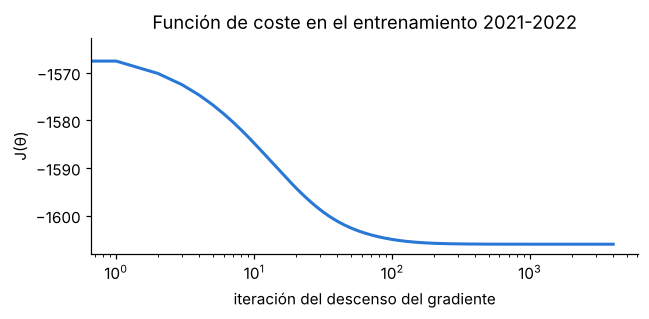

In [ ]:
from sklearn.linear_model import PoissonRegressor

media, desv = escalas(dev_m, candidatas)
X = matriz(dev_m, media, desv, candidatas)
y = dev_m["total"].values
esf = dev_m["esfuerzo"].values
theta, costes = ajustar_poisson(X, y, esf, historia=True)
sk = PoissonRegressor(alpha=0, max_iter=2000).fit(X[:, 1:], y / esf, sample_weight=esf)
print("descenso del gradiente", theta.round(3))
print("scikit-learn          ", np.r_[sk.intercept_, sk.coef_].round(3))
print("J en las iteraciones 0, 100, 300, 1000 y 4000", np.array(costes)[[0, 100, 300, 1000, -1]].round(2))

mu = predecir(theta, X, esf)
print("dispersión", round(np.sum((y - mu) ** 2 / mu) / (len(y) - X.shape[1]), 1))
tercio = pd.qcut(mu, 3, labels=["bajo", "medio", "alto"])
print("dispersión por tercio de la media predicha", pd.Series((y - mu) ** 2 / mu).groupby(tercio, observed=True).mean().round(0).to_dict())

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(np.arange(len(costes)), costes, color=azul, lw=2)
ax.set_xscale("log")
ax.set_xlabel("iteración del descenso del gradiente")
ax.set_ylabel("J(θ)")
ax.set_title("Función de coste en el entrenamiento 2021-2022")
plt.tight_layout()
plt.show()

J baja de −1564.74 a −1604.99 en las primeras 100 iteraciones y a −1605.93 a las 300, y después casi no cambia. Los coeficientes coinciden con los de scikit-learn, así que el descenso del gradiente si llega al mínimo.

La dispersión es 141, no 1, y crece con la media predicha. Los conteos varían unas 141 veces más de lo que permite una Poisson. Eso no daña la predicción del promedio. Las ecuaciones que resuelve el ajuste solo exigen que la media esté bien especificada, y son las mismas si la varianza es 141μ en vez de μ. Lo que deja de valer es la incertidumbre asociada a esta distribucion. Sus errores estándar quedarían unas √141 ≈ 12 veces cortos y hariamos una mala estimacion. Como además la dispersión crece con la media, tampoco basta con corregirlo por un factor que podamos definir. Entonces es necesario definir otra estrategia para cuantificar el error

## 4.6 Selección de variables

Que las seis candidatas tengan sentido no significa que todas ayuden a predecir campañas nuevas. Empezamos analizando solo con historico, porque el sitio es lo que más pesa. En cada paso probamos agregar cada variable que falta, nos quedamos con la que deja más campañas dentro del factor 2 y repetimos hasta usarlas todas. sin_mes y cos_mes entran juntas como mes, porque cada una sola no describe el mes. Si dos variables empatan, entra primero la de la agrupación con mayor R² en la sección 3.3, en este orden: lag1 (conglomerado), neiv_hist (segmento), regional (ronda) y mes.

La regla de decisión es quedarnos con el conjunto más pequeño cuya fracción dentro del factor 2 esté a menos de 0.02 del mejor. Con 160 campañas cada una vale 0.006, así que 0.02 son unas 3 campañas, mucho menos que el ancho de los intervalos de las diferencias entre modelos. Buscando utilizar la menor cantidad de variables.

In [ ]:
bloques = {"lag1": ["lag1"], "neiv_hist": ["neiv_hist"], "regional": ["regional"], "mes": ["sin_mes", "cos_mes"]}

def f2_validacion(cols):
    v = validar(dev_m, cols)
    return metricas(v["total"], v["Poisson"])["dentro factor 2"]

elegidas, restantes = ["historico"], list(bloques)
camino = [{"paso": 0, "se agrega": "historico", "dentro factor 2": f2_validacion(elegidas)}]
intentos = {}
while restantes:
    prueba_paso = {b: f2_validacion(elegidas + bloques[b]) for b in restantes}
    intentos[len(camino)] = prueba_paso
    mejor = max(prueba_paso, key=prueba_paso.get)
    elegidas = elegidas + bloques[mejor]
    restantes.remove(mejor)
    camino.append({"paso": len(camino), "se agrega": mejor, "dentro factor 2": prueba_paso[mejor]})

camino = pd.DataFrame(camino).set_index("paso")
print("cada fila prueba agregar una variable al conjunto del paso anterior")
print(pd.DataFrame(intentos).T.round(3).fillna("").to_string())
print()
print(camino.round(3).to_string())

mejor_f2 = camino["dentro factor 2"].max()
paso_elegido = camino.index[mejor_f2 - camino["dentro factor 2"] < 0.02][0]
feats = ["historico"] + sum([bloques[b] for b in camino.loc[1:paso_elegido, "se agrega"]], [])
print("mejor fracción", round(mejor_f2, 3), " paso elegido", paso_elegido, " variables", feats)

cada fila prueba agregar una variable al conjunto del paso anterior
  lag1 neiv_hist  regional    mes
1  0.7     0.681     0.681    0.7
2          0.688     0.681  0.719
3          0.706     0.688       
4                    0.694       

      se agrega  dentro factor 2
paso                            
0     historico            0.688
1          lag1            0.700
2           mes            0.719
3     neiv_hist            0.706
4      regional            0.694
mejor fracción 0.719  paso elegido 1  variables ['historico', 'lag1']


Con historico solo, el modelo deja 0.688 de las campañas dentro del factor 2. En el primer paso lag1 y mes empatan en 0.700, y por la regla de empate entra lag1. Con historico, lag1 y mes se llega al máximo, 0.719. Agregar después neiv_hist (0.706) y regional (0.694) empeora la validación, y el modelo con las seis candidatas, que era nuestro punto de partida, queda en 0.694. historico con lag1 está a 0.019 del mejor (3 campañas) y cumple la regla; historico solo está a 0.031 y no la cumple. Nos quedamos con dos variables, historico y lag1.

Una vez se conoce el historial del sitio, las demás variables no agregan nada que se distinga de 3 campañas en 160. El mes queda en el límite, porque con él se ganan justo 3 campañas.

## 4.7 Evaluación en la validación de 2022

Con historico y lag1 comparamos los cinco modelos en las mismas 160 campañas de 2022. Para saber si una diferencia es real remuestreamos conglomerados completos (bootstrap por bloques), porque las campañas de un mismo sitio no son independientes. La última columna es el intervalo del 95% de la diferencia entre Poisson y cada modelo en la fracción dentro del factor 2.

In [ ]:
def dentro(res, col):
    return (np.abs(np.log((res["total"] + 1) / (res[col] + 1))) < np.log(2)).astype(float)

def ic_diferencia(res, a, b, grupo="cluster", n=2000):
    # remuestrea grupos completos (conglomerados o rondas) y no campañas sueltas
    d = (dentro(res, a) - dentro(res, b)).groupby(res[grupo]).agg(["sum", "size"])
    difs = []
    for _ in range(n):
        i = rng.integers(0, len(d), len(d))
        difs.append(d["sum"].values[i].sum() / d["size"].values[i].sum())
    return np.quantile(difs, [0.025, 0.975])

modelos = ["tasa típica", "persistencia", "promedio del sitio", "lineal", "Poisson"]
val = validar(dev_m, feats)
val["error_log"] = np.log((val["total"] + 1) / (val["Poisson"] + 1))
tabla_val = pd.DataFrame({m: metricas(val["total"], val[m]) for m in modelos}).T
tabla_val["Poisson menos este, IC 95%"] = [str(ic_diferencia(val, "Poisson", m).round(3)) if m != "Poisson" else "" for m in modelos]
print(len(val), "campañas predichas en", val["ronda"].nunique(), "rondas;", val["lineal negativa"].sum(), "tasas negativas de la lineal (se cuentan como 0)")
tabla_val.round(3)

160 campañas predichas en 10 rondas; 9 tasas negativas de la lineal (se cuentan como 0)


,dentro factor 2,error típico (factor),error relativo (%),"Poisson menos este, IC 95%"
tasa típica,0.494,2.046,62.914,[0.088 0.338]
persistencia,0.619,1.674,52.160,[-0.006 0.156]
promedio del sitio,0.662,1.643,52.249,[-0.044 0.112]
lineal,0.606,1.653,49.600,[0.025 0.175]
Poisson,0.700,1.635,48.379,


La regresión de Poisson deja el 70.0% de las campañas dentro del factor 2, el promedio del sitio el 66.2%, la persistencia el 61.9%, la lineal el 60.6% y la tasa típica de Timbiquí el 49.4%. Poisson le gana con claridad a la tasa típica (la diferencia va de 0.088 a 0.338) y a la lineal (de 0.025 a 0.175). Contra la persistencia (de −0.006 a 0.156) y contra el promedio del sitio (de −0.044 a 0.112) el intervalo incluye el cero, así que no podemos decir que sea mejor que promediar lo que el sitio ha capturado antes. La lineal dio 9 tasas negativas, algo esperable al suponer ruido gaussiano sobre un conteo, y queda por debajo del promedio del sitio aunque usa la misma información. El error típico es parecido en los cuatro modelos que usan el historial, un factor entre 1.6 y 1.7. En error relativo la Poisson se equivoca en 48 de cada 100 mosquitos, la lineal en 50, el promedio del sitio y la persistencia en 52 y la tasa típica en 63.

## 4.8 Qué dice el modelo

El modelo ajustado con todas las campañas de 2021 y 2022 tiene tres números: θ0 y un coeficiente por variable. Como las variables están estandarizadas, exp(θ_j) es el factor por el que se multiplica la tasa predicha cuando esa variable sube una desviación estándar y la otra no cambia.

In [ ]:
media, desv = escalas(dev_m, feats)
X = matriz(dev_m, media, desv, feats)
theta_dev = ajustar_poisson(X, y, esf)
coefs = pd.DataFrame({"desviación": desv, "10^desviación": 10 ** desv, "θ": theta_dev[1:], "exp(θ)": np.exp(theta_dev[1:]),
                      "exponente b": theta_dev[1:] / (desv * np.log(10))}, index=feats)
print("θ0 =", round(theta_dev[0], 3), "  exp(θ0) =", round(np.exp(theta_dev[0]), 1), "mosquitos por noche en un sitio con todas las variables en su promedio")
print(coefs.round(3))
C = np.exp(theta_dev[0] - np.sum(theta_dev[1:] * media / desv))
print("forma equivalente: tasa = C · 10^(b1·historico) · 10^(b2·lag1), con C =", round(C, 2), " y b1 + b2 =", round(coefs["exponente b"].sum(), 2))

θ0 = 4.452   exp(θ0) = 85.8 mosquitos por noche en un sitio con todas las variables en su promedio
           desviación  10^desviación      θ  exp(θ)  exponente b
historico       0.286          1.934  0.328   1.388        0.497
lag1            0.426          2.668  0.238   1.269        0.243
forma equivalente: tasa = C · 10^(b1·historico) · 10^(b2·lag1), con C = 3.93  y b1 + b2 = 0.74


exp(θ0) = 85.8 es la tasa predicha, en mosquitos por noche, para un sitio con historico y lag1 en su promedio. La desviación de historico es 0.286 en log10, que corresponde a una tasa histórica 1.93 veces mayor, y un sitio con ese historial más alto recibe una predicción exp(0.328) = 1.39 veces mayor. La desviación de lag1 es 0.426, una campaña anterior 2.67 veces mayor, que multiplica la predicción por exp(0.238) = 1.27. Por desviación estándar historico pesa más que lag1, como se esperaba de la sección 3.3, donde el nivel del sitio explicaba mucho y la memoria de una visita a la siguiente poco.

Como las dos variables son logaritmos de tasas, el modelo sin estandarizar es una ley de potencias,

$$\text{tasa predicha} = C\cdot\left(10^{\text{historico}}\right)^{b_1}\left(10^{\text{lag1}}\right)^{b_2},\qquad b_j = \frac{\theta_j}{s_j \ln 10},$$

con s_j la desviación de la variable. 10^historico es la media geométrica de (tasa + 1) en las campañas anteriores y 10^lag1 es (tasa + 1) en la campaña anterior. Con los valores ajustados, C = 3.93, b1 = 0.497 y b2 = 0.243, queda

$$\text{tasa predicha} \approx 3.93\,\left(10^{\text{historico}}\right)^{0.50}\left(10^{\text{lag1}}\right)^{0.24}.$$

Como b1 + b2 = 0.74 es menor que 1, un sitio que siempre captura 10 veces más que otro recibe una predicción unas 10^0.74 ≈ 5.5 veces mayor, no 10 veces. El modelo acerca todos los sitios al promedio, y en la sección 4.12 vemos ese sesgo en campañas nuevas.

Para ver la cuenta completa tomamos la próxima visita de Chete 1 vista desde diciembre de 2022, su campaña de 4 noches de enero de 2023. Sus variables se conocen antes de la visita, y el total observado no lo miramos hasta la sección 4.13.

In [ ]:
ejemplo = final_m[final_m["cluster"] == "Chete1"].iloc[0]   # primera visita de 2023, vista desde diciembre de 2022
valores = ejemplo[feats].values.astype(float)
z = (valores - media) / desv
cuenta = pd.DataFrame({"valor": valores, "media": media, "desviación": desv, "z": z, "θ": theta_dev[1:], "θ·z": theta_dev[1:] * z}, index=feats)
print("Chete1, ronda", ejemplo["ronda"], " noches", ejemplo["noches"], " esfuerzo", round(ejemplo["esfuerzo"], 2))
print(cuenta.round(3))
suma = theta_dev[0] + np.sum(theta_dev[1:] * z)
print("θᵀx = θ0 + suma de θ·z =", round(theta_dev[0], 3), "+", round(np.sum(theta_dev[1:] * z), 3), "=", round(suma, 3))
print("tasa por noche exp(θᵀx) =", round(np.exp(suma), 1))
print("predicción = esfuerzo · tasa =", round(ejemplo["esfuerzo"], 2), "·", round(np.exp(suma), 1), "=", round(ejemplo["esfuerzo"] * np.exp(suma), 1))
print("misma cuenta con la forma equivalente", round(C * np.prod(10 ** (coefs["exponente b"].values * valores)) * ejemplo["esfuerzo"], 1))
print("promedio del sitio para la misma visita", round((10 ** ejemplo["historico"] - 1) * ejemplo["esfuerzo"], 1))

Chete1, ronda 2023-01  noches 4  esfuerzo 4.0
           valor  media  desviación      z      θ    θ·z
historico  1.826  1.807       0.286  0.067  0.328  0.022
lag1       1.708  1.813       0.426 -0.248  0.238 -0.059
θᵀx = θ0 + suma de θ·z = 4.452 + -0.037 = 4.415
tasa por noche exp(θᵀx) = 82.6
predicción = esfuerzo · tasa = 4.0 · 82.6 = 330.6
misma cuenta con la forma equivalente 330.6
promedio del sitio para la misma visita 264.2


 Historico vale 1.826, apenas por encima de la media del entrenamiento (1.807), así que z = (1.826 − 1.807)/0.286 = 0.067 y aporta 0.328 × 0.067 = 0.022. lag1 vale 1.708, porque diciembre de 2022 fue algo bajo para Chete 1, así que z = −0.248 y aporta −0.059. Sumando, θᵀx = 4.452 + 0.022 − 0.059 = 4.415. La tasa es e^4.415 = 82.6 mosquitos por noche, y con 4 noches la predicción es 330.6 mosquitos. Con la ley de potencias sale lo mismo: 3.93 · 10^(0.497 · 1.826) · 10^(0.243 · 1.708) · 4 ≈ 331.

El promedio del sitio para la misma visita es 264, así que el modelo queda un 25% por encima aunque el historial de Chete 1 está casi en el promedio. La figura siguiente muestra de dónde sale esa diferencia: compara, para cada campaña de entrenamiento, la tasa predicha con la tasa histórica del sitio.

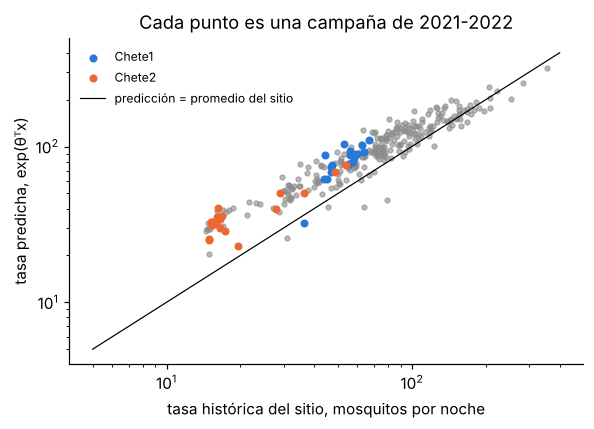

pendiente de log(tasa predicha) contra log(tasa histórica) 0.74
suma de lo predicho / suma de lo observado en el entrenamiento 1.0
mediana de observado / predicho en el entrenamiento 0.78
tasa predicha / tasa histórica, mediana 1.38


In [ ]:
tasa_hist = 10 ** dev_m["historico"] - 1
tasa_pred = np.exp(X @ theta_dev)
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.scatter(tasa_hist, tasa_pred, s=10, color=gris, alpha=0.6)
for c, col in [("Chete1", azul), ("Chete2", naranja)]:
    s = dev_m["cluster"] == c
    ax.scatter(tasa_hist[s], tasa_pred[s], s=18, color=col, label=c)
lim = [5, 400]
ax.plot(lim, lim, "k-", lw=0.8, label="predicción = promedio del sitio")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("tasa histórica del sitio, mosquitos por noche")
ax.set_ylabel("tasa predicha, exp(θᵀx)")
ax.set_title("Cada punto es una campaña de 2021-2022")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()
mu_dev = predecir(theta_dev, X, esf)
print("pendiente de log(tasa predicha) contra log(tasa histórica)", round(np.polyfit(np.log(tasa_hist), np.log(tasa_pred), 1)[0], 2))
print("suma de lo predicho / suma de lo observado en el entrenamiento", round(mu_dev.sum() / y.sum(), 3))
print("mediana de observado / predicho en el entrenamiento", round(np.median((y + 1) / (mu_dev + 1)), 2))
print("tasa predicha / tasa histórica, mediana", round(np.median(tasa_pred / tasa_hist), 2))

Los puntos forman una banda con pendiente 0.74 (que es b1 + b2), más plana que la diagonal, y casi todos quedan por encima de ella. Que queden por encima viene de la función de coste. El gradiente respecto a θ0 igual a cero obliga a que la suma de lo predicho sea igual a la suma de lo observado (en el entrenamiento la razón da 1.0), es decir, la Poisson apunta a la media aritmética de los conteos. Con ruido multiplicativo la media aritmética queda por encima de la campaña típica. Por eso la tasa predicha es en mediana 1.38 veces la histórica, que es geométrica, y lo observado es en mediana 0.78 veces lo predicho. Chete 2 es el punto más bajo de Timbiquí y ahí se suman los dos efectos, así que el modelo le predice más de lo que suele capturar.

## 4.9 Curva de aprendizaje y sobreajuste

Para saber si el modelo sobreajusta o le faltan datos hacemos dos comparaciones. La primera es una curva de aprendizaje. Dejamos fija la validación en las 160 campañas de 2022, entrenamos con cada vez más rondas de 2021, las 2 primeras, las 3 primeras, y así hasta las 8; y medimos la fracción dentro del factor 2 en el entrenamiento y en la validación. La segunda hace una comparacion, dentro del origen que es móvil, el acierto en las campañas con que se entrenó cada ajuste y en la ronda que predijo. Si el modelo memoriza, el entrenamiento quedara muy por encima de la validación.

 rondas de 2021  campañas  entrenamiento  validación 2022
              2        32          0.594            0.619
              3        48          0.604            0.688
              4        64          0.625            0.688
              5        78          0.577            0.638
              6        94          0.596            0.625
              7       110          0.618            0.644
              8       125          0.624            0.644


origen móvil: entrenamiento, promedio de las 10 rondas 0.624  validación 0.7
ajuste con todo 2021-2022, campañas de 2021 dentro del factor 2 0.552
ajuste con todo 2021-2022, campañas de 2022 dentro del factor 2 0.669


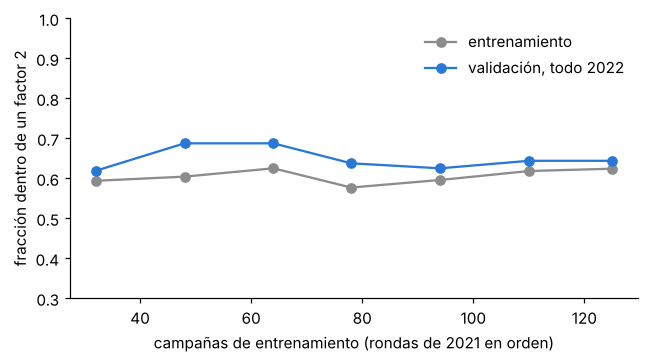

In [ ]:
rondas_2021 = sorted(dev_m.loc[dev_m["ronda"] < rondas_val[0], "ronda"].unique())
valida_2022 = dev_m[dev_m["ronda"] >= rondas_val[0]]
filas = []
for k in range(2, len(rondas_2021) + 1):
    e = dev_m[dev_m["ronda"].isin(rondas_2021[:k])]
    m_, d_ = escalas(e, feats)
    th = ajustar_poisson(matriz(e, m_, d_, feats), e["total"].values, e["esfuerzo"].values)
    filas.append({"rondas de 2021": k, "campañas": len(e),
                  "entrenamiento": metricas(e["total"], predecir(th, matriz(e, m_, d_, feats), e["esfuerzo"].values))["dentro factor 2"],
                  "validación 2022": metricas(valida_2022["total"], predecir(th, matriz(valida_2022, m_, d_, feats), valida_2022["esfuerzo"].values))["dentro factor 2"]})
curva = pd.DataFrame(filas)
print(curva.round(3).to_string(index=False))

entreno_movil = []
for r in rondas_val:
    e = dev_m[dev_m["ronda"] < r]
    m_, d_ = escalas(e, feats)
    th = ajustar_poisson(matriz(e, m_, d_, feats), e["total"].values, e["esfuerzo"].values)
    entreno_movil.append(metricas(e["total"], predecir(th, matriz(e, m_, d_, feats), e["esfuerzo"].values))["dentro factor 2"])
print("origen móvil: entrenamiento, promedio de las 10 rondas", round(np.mean(entreno_movil), 3),
      " validación", round(metricas(val["total"], val["Poisson"])["dentro factor 2"], 3))
anio = dev_m["inicio"].dt.year.values
for a in [2021, 2022]:
    print("ajuste con todo 2021-2022, campañas de", a, "dentro del factor 2",
          round(metricas(y[anio == a], predecir(theta_dev, X, esf)[anio == a])["dentro factor 2"], 3))

c = curva
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(c["campañas"], c["entrenamiento"], "o-", color=gris, label="entrenamiento")
ax.plot(c["campañas"], c["validación 2022"], "o-", color=azul, label="validación, todo 2022")
ax.set_ylim(0.3, 1)
ax.set_xlabel("campañas de entrenamiento (rondas de 2021 en orden)")
ax.set_ylabel("fracción dentro de un factor 2")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

No hay sobreajuste. Con 32 campañas de entrenamiento el acierto es 0.594 en entrenamiento y 0.619 en validación, y con las 125 campañas de 2021 queda en 0.624 y 0.644. Las dos curvas son casi planas y la validación queda incluso por encima del entrenamiento. En el origen móvil pasa lo mismo: 0.624 en entrenamiento (promedio de las 10 rondas) contra 0.700 en validación. La validación con todo 2021 (0.644) queda por debajo de la del origen móvil porque en el origen móvil cada ronda de 2022 también aprende de las rondas anteriores de 2022.

Una parte de por qué el entrenamiento queda por debajo sí la comprobamos. En el ajuste con todo 2021 y 2022, las campañas de 2021 quedan dentro del factor 2 en 0.552 y las de 2022 en 0.669, así que 2021 es más difícil de predecir incluso para el modelo que la vio. Una explicación posible, que no probamos, es que en 2021 el historico de cada sitio sale de pocas visitas y que en ese año está la caída de septiembre.

El modelo no está limitado por la complejidad, porque con dos coeficientes no tiene con qué memorizar y en la sección 4.6 más variables no ayudaron. Tampoco por los datos, porque más rondas de 2021 no mueven la validación. Lo limita el ruido. Ni siquiera en las campañas con que se entrenó pone más de unas 6 de cada 10 dentro del factor 2, y lo que queda es variación de una campaña a otra que el historial del sitio no anticipa.

## 4.10 Qué variable usa más el modelo

Usamos importancia por permutaciones. En cada ronda de validación barajamos una variable entre las campañas que se predicen, con el modelo ya entrenado, y medimos cuánto baja la fracción dentro del factor 2. Lo repetimos 20 veces por ronda.

In [ ]:
perdida = {f: 0.0 for f in feats}
for r in rondas_val:
    e = dev_m[dev_m["ronda"] < r]
    p = dev_m[dev_m["ronda"] == r]
    m_, d_ = escalas(e, feats)
    th = ajustar_poisson(matriz(e, m_, d_, feats), e["total"].values, e["esfuerzo"].values)
    base = dentro(p.assign(pred=predecir(th, matriz(p, m_, d_, feats), p["esfuerzo"].values)), "pred").sum()
    for f in feats:
        for rep in range(20):
            q = p.copy()
            q[f] = rng.permutation(q[f].values)
            perdida[f] += (base - dentro(q.assign(pred=predecir(th, matriz(q, m_, d_, feats), q["esfuerzo"].values)), "pred").sum()) / (20 * len(val))
print(pd.Series(perdida).round(3).sort_values(ascending=False).to_string())

historico    0.206
lag1         0.034


Barajar historico baja la fracción en 0.206 y barajar lag1 en 0.034. El modelo descansa casi todo en el historial del sitio y lag1 es una corrección pequeña. Parte de lo que dice lag1 ya está en historico , y al barajar solo lag1 esa parte sigue llegando por historico, así que esta medida no se la atribuye a lag1.

## 4.11 Incertidumbre

La incertidumbre de la Poisson no sirve por la sobredispersión. Construimos el intervalo del 80% con los errores de la validación de 2022. Si el 10% de las veces lo observado quedó por debajo de la predicción en más de cierto factor, usamos ese factor hacia abajo, y lo mismo hacia arriba con el percentil 90. Ese intervalo contiene por construcción al 80% de la validación, así que lo comprobamos. Para cada ronda calculamos los percentiles solo con los errores de las rondas anteriores.

Para ver de dónde viene la incertidumbre usamos un bootstrap por conglomerados. En cada ronda de validación remuestreamos conglomerados del entrenamiento, reajustamos 60 veces y miramos cuánto se mueve la predicción, lo que mide solo la incertidumbre de los parámetros. Después le sumamos a cada predicción remuestreada un residuo sorteado del entrenamiento, que agrega el ruido entre campañas.

In [ ]:
q10, q90 = np.quantile(val["error_log"], [0.1, 0.9])
print("factor hacia abajo", round(np.exp(q10), 2), " mediana", round(np.exp(np.median(val["error_log"])), 2), " factor hacia arriba", round(np.exp(q90), 2))

def intervalo(pred):
    return (pred + 1) * np.exp(q10) - 1, (pred + 1) * np.exp(q90) - 1

# comprobación secuencial: percentiles con los errores de las rondas anteriores
cubre, anchos = [], []
for r in rondas_val[1:]:
    a, b_ = np.quantile(val.loc[val["ronda"] < r, "error_log"], [0.1, 0.9])
    actual = val.loc[val["ronda"] == r, "error_log"]
    cubre += list((actual >= a) & (actual <= b_))
    anchos.append(np.exp(b_ - a))

# bootstrap por conglomerados, con la misma validación secuencial
def ajustes_bootstrap(entreno, n):
    bloques_c = {c: entreno[entreno["cluster"] == c] for c in entreno["cluster"].unique()}
    nombres = list(bloques_c)
    ajustes = []
    for _ in range(n):
        m = pd.concat([bloques_c[c] for c in rng.choice(nombres, len(nombres))])
        m_, d_ = escalas(m, feats)
        ajustes.append((ajustar_poisson(matriz(m, m_, d_, feats), m["total"].values, m["esfuerzo"].values, iteraciones=1500), m_, d_))
    return ajustes

cubre_par, cubre_ruido, ancho_par, ancho_ruido = [], [], [], []
for r in rondas_val:
    e = dev_m[dev_m["ronda"] < r]
    p = dev_m[dev_m["ronda"] == r]
    m_, d_ = escalas(e, feats)
    th = ajustar_poisson(matriz(e, m_, d_, feats), e["total"].values, e["esfuerzo"].values)
    residuos = np.log((e["total"].values + 1) / (predecir(th, matriz(e, m_, d_, feats), e["esfuerzo"].values) + 1))
    P = np.array([predecir(t, matriz(p, mb, db, feats), p["esfuerzo"].values) for t, mb, db in ajustes_bootstrap(e, 60)])
    lo, hi = np.quantile(P, [0.1, 0.9], axis=0)
    cubre_par += list((p["total"].values >= lo) & (p["total"].values <= hi))
    ancho_par += list((hi + 1) / (lo + 1))
    S = (P[:, :, None] + 1) * np.exp(rng.choice(residuos, (P.shape[0], P.shape[1], 30))) - 1
    lo, hi = np.quantile(S.transpose(1, 0, 2).reshape(P.shape[1], -1), [0.1, 0.9], axis=1)
    cubre_ruido += list((p["total"].values >= lo) & (p["total"].values <= hi))
    ancho_ruido += list((hi + 1) / (lo + 1))

tabla_inc = pd.DataFrame({
    "cobertura": [np.mean(cubre), np.mean(cubre_par), np.mean(cubre_ruido)],
    "ancho típico (factor)": [np.mean(anchos), np.median(ancho_par), np.median(ancho_ruido)],
    "campañas": [len(cubre), len(cubre_par), len(cubre_ruido)],
}, index=["empírico secuencial", "bootstrap, solo parámetros", "bootstrap, parámetros más residuos"])
print("intervalos del 80% en la validación de 2022")
print(tabla_inc.round(3))

factor hacia abajo 0.38  mediana 0.91  factor hacia arriba 2.27


intervalos del 80% en la validación de 2022
                                    cobertura  ancho típico (factor)  campañas
empírico secuencial                     0.771                  6.440       144
bootstrap, solo parámetros              0.156                  1.307       160
bootstrap, parámetros más residuos      0.788                  6.853       160


El intervalo va de 0.38 a 2.27 veces la predicción.Tiende hacia abajo porque en mediana lo observado fue 0.91 veces lo predicho, por la misma tendencia a apuntar a la media aritmética que vimos en la sección 4.8. La comprobación secuencial cubre al 77.1% de 144 campañas, cerca del 80% sin haber usado 2023. El bootstrap de solo parámetros cubre apenas al 15.6%, con un ancho de factor 1.3, porque mide qué tan bien conocemos los dos coeficientes y no cuánto varía una campaña. Al sumar el ruido la cobertura sube a 78.8% con un ancho de 6.9, parecido al del intervalo empírico (6.4). Casi toda la incertidumbre es ruido entre campañas y muy poca viene de los coeficientes, así que nos quedamos con el intervalo empírico, que es el más simple.

## 4.12 Con qué datos aprende

Los coeficientes del modelo son una sola regla para todos los sitios y se aprenden con todas las campañas del entrenamiento. Las variables, en cambio, salen del historial de cada punto, así que para Cheté la regla se evalúa con el pasado de Chete 1 y Chete 2. Falta decidir con qué sitios aprender la regla. Comparamos cuatro opciones en las mismas 20 campañas de Cheté de la validación de 2022,todo el estudio , Timbiquí, los 4 conglomerados de albimanus y solo Cheté. Como Cheté tiene solo dos conglomerados, el intervalo de las diferencias remuestrea rondas.

In [ ]:
modelable_todo = preparar(camp_todo)
modelable_todo["guapi"] = (modelable_todo["municipio"] == "Guapi") * 1.0
modelable_todo["sbarbara"] = (modelable_todo["municipio"] == "Santa Bárbara") * 1.0
dev_todo = modelable_todo[modelable_todo["inicio"] < corte]
albimanus_sitios = list(sitios.index[sitios["segmento"] == "albimanus"])

opciones = {
    "todo el estudio": validar(dev_todo, feats + ["guapi", "sbarbara"]),
    "Timbiquí": val,
    "4 de albimanus": validar(dev_m[dev_m["cluster"].isin(albimanus_sitios)], feats),
    "solo Cheté": validar(dev_m[dev_m["localidad"] == "Cheté"], feats),
}
claves = ["cluster", "ronda", "total"]
en_chete = val.loc[val["localidad"] == "Cheté", claves + ["promedio del sitio"]]
for nombre, v in opciones.items():
    en_chete = en_chete.merge(v[claves + ["Poisson"]].rename(columns={"Poisson": nombre}), on=claves)
filas = {}
for nombre in list(opciones) + ["promedio del sitio"]:
    filas[nombre] = metricas(en_chete["total"], en_chete[nombre])
    filas[nombre]["Timbiquí menos este, IC 95%"] = "" if nombre == "Timbiquí" else str(ic_diferencia(en_chete, "Timbiquí", nombre, grupo="ronda").round(2))
print(len(en_chete), "campañas de Cheté validadas;", "conglomerados de albimanus", albimanus_sitios)
pd.DataFrame(filas).T.round(3)

20 campañas de Cheté validadas; conglomerados de albimanus ['Chete1', 'Chete2', 'Coteje1', 'Coteje2']


,dentro factor 2,error típico (factor),error relativo (%),"Timbiquí menos este, IC 95%"
todo el estudio,0.75,1.632618,43.746854,[0. 0.15]
Timbiquí,0.8,1.530823,43.379301,
4 de albimanus,0.7,1.39439,42.080409,[-0.1 0.25]
solo Cheté,0.75,1.553828,38.906981,[-0.25 0.3 ]
promedio del sitio,0.7,1.415608,43.114217,[-0.2 0.4]


En las 20 campañas de Cheté, donde cada una vale 0.05, entrenar con Timbiquí deja 0.80 dentro del factor 2. Con todo el estudio y con solo Cheté se obtiene 0.75, y con los 4 de albimanus 0.70, lo mismo que el promedio del sitio. Ningún intervalo de la diferencia excluye el cero , así que con tan pocas campañas los datos no obligan a ninguna opción. Los 4 de albimanus tienen el menor error típico (1.39). Nos quedamos con Timbiquí, que fue la decisión anterior y queda en un punto intermedio entre aprender de muchos sitios distintos y aprender solo de los dos puntos de Cheté que pensamos que seria insuficiente.

correlación entre el nivel del conglomerado y su error medio 0.59
factor observado / predicho {'Chete1': 1.29, 'Chete2': 0.6}


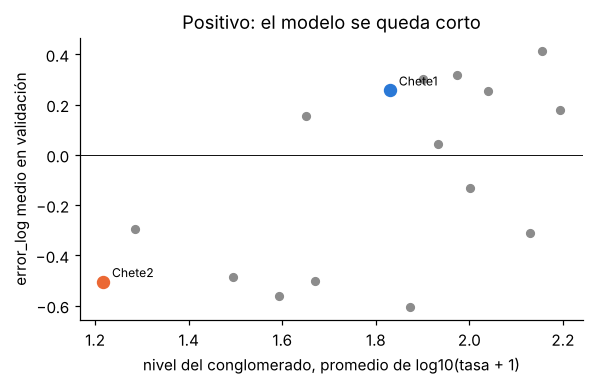

In [ ]:
sesgo = val.groupby("cluster")["error_log"].mean()
nivel = dev_m.groupby("cluster")["ltasa"].mean().loc[sesgo.index]
print("correlación entre el nivel del conglomerado y su error medio", round(np.corrcoef(nivel, sesgo)[0, 1], 2))
print("factor observado / predicho", np.exp(sesgo[["Chete1", "Chete2"]]).round(2).to_dict())

fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.scatter(nivel, sesgo, color=gris, s=25)
for c, col in [("Chete1", azul), ("Chete2", naranja)]:
    ax.scatter(nivel[c], sesgo[c], color=col, s=60, zorder=3)
    ax.annotate(c, (nivel[c], sesgo[c]), xytext=(6, 3), textcoords="offset points", fontsize=8)
ax.axhline(0, color="k", lw=0.6)
ax.set_xlabel("nivel del conglomerado, promedio de log10(tasa + 1)")
ax.set_ylabel("error_log medio en validación")
ax.set_title("Positivo: el modelo se queda corto")
plt.tight_layout()
plt.show()

La correlación entre el nivel del conglomerado y su error medio es 0.59. Los sitios altos quedan cortos y los bajos se pasan; es la pendiente 0.74 de la sección 4.8, vista ahora en campañas nuevas. En Cheté el error va en direcciones opuestas: en la validación lo observado fue en promedio 1.29 veces lo predicho en Chete 1 y 0.60 veces en Chete 2. En el total de Cheté los dos errores se compensan en parte, pero la diferencia real entre los dos puntos es mayor que la que da el modelo. El promedio del sitio no mezcla sitios y no tiene este problema, lo que ayuda a entender por qué el modelo no le gana.

## 4.13 Evaluación final en las campañas reservadas

Trabajamos con las variables historico y lag1, entrenamos con Timbiquí e en un intervalo que decidimos. Con el ajuste de 2021 y 2022 predecimos una sola vez las 48 campañas de enero a marzo de 2023. Las variables de cada campaña de 2023 usan lo que se sabía antes de ella, incluida la campaña anterior aunque sea de 2023, pero los coeficientes quedan fijos. Al final comparamos el acierto en entrenamiento, validación y prueba.

In [ ]:
Xf = matriz(final_m, media, desv, feats)
prueba_final = final_m[["cluster", "localidad", "ronda", "total", "esfuerzo"]].copy()
prueba_final["tasa típica"] = dev_m["tasa"].median() * final_m["esfuerzo"]
prueba_final["persistencia"] = (10 ** final_m["lag1"] - 1) * final_m["esfuerzo"]
prueba_final["promedio del sitio"] = (10 ** final_m["historico"] - 1) * final_m["esfuerzo"]
prueba_final["lineal"] = np.clip(Xf @ ajustar_lineal(X, dev_m["tasa"].values), 0, None) * final_m["esfuerzo"]
prueba_final["Poisson"] = predecir(theta_dev, Xf, final_m["esfuerzo"].values)
bajo, alto = intervalo(prueba_final["Poisson"])
prueba_final["dentro del 80%"] = (prueba_final["total"] >= bajo) & (prueba_final["total"] <= alto)

tabla_final = pd.DataFrame({m: metricas(prueba_final["total"], prueba_final[m]) for m in modelos}).T
tabla_final["Poisson menos este, IC 95%"] = [str(ic_diferencia(prueba_final, "Poisson", m).round(3)) if m != "Poisson" else "" for m in modelos]
print(len(prueba_final), "campañas reservadas, cobertura del intervalo del 80%", round(prueba_final["dentro del 80%"].mean(), 3))
print(tabla_final.round(3).to_string())
print()
tres = pd.DataFrame({
    "entrenamiento 2021-2022": metricas(dev_m["total"], predecir(theta_dev, X, esf)),
    "validación 2022, origen móvil": metricas(val["total"], val["Poisson"]),
    "prueba 2023": metricas(prueba_final["total"], prueba_final["Poisson"]),
}).T
tres["campañas"] = [len(dev_m), len(val), len(prueba_final)]
print(tres.round(3).to_string())
print()
print(prueba_final.loc[prueba_final["localidad"] == "Cheté", ["cluster", "ronda", "total", "Poisson", "promedio del sitio", "dentro del 80%"]].round({"Poisson": 0, "promedio del sitio": 0}).to_string(index=False))

48 campañas reservadas, cobertura del intervalo del 80% 0.875
                    dentro factor 2  error típico (factor)  error relativo (%) Poisson menos este, IC 95%
tasa típica                   0.521                  1.917              60.038              [0.104 0.458]
persistencia                  0.771                  1.631              48.386            [-0.125  0.167]
promedio del sitio            0.812                  1.366              39.227            [-0.146  0.104]
lineal                        0.771                  1.364              41.731              [0.    0.062]
Poisson                       0.792                  1.503              40.452                           

                               dentro factor 2  error típico (factor)  error relativo (%)  campañas
entrenamiento 2021-2022                  0.618                  1.637              50.285       285
validación 2022, origen móvil            0.700                  1.635              48.379       160
p

En las 48 campañas de 2023 el promedio del sitio deja 0.812 dentro del factor 2, Poisson 0.792, la persistencia y la lineal 0.771 y la tasa típica de Timbiquí 0.521. Poisson solo le gana con claridad a la tasa típica (de 0.104 a 0.458) y queda en el borde contra la lineal (de 0.000 a 0.062). Contra el promedio del sitio la diferencia va de −0.146 a 0.104, y el promedio del sitio tiene menor error típico (1.37 contra 1.50). En error relativo el promedio del sitio se equivoca en 39 de cada 100 mosquitos, la Poisson en 40, la lineal en 42, la persistencia en 48 y la tasa típica en 60. El intervalo del 80% cubrió al 87.5% de las campañas. Quedó algo más ancho de lo necesario, y para comprar insumos eso es preferible a quedarse corto.

La tabla de tres filas confirma lo de la sección 4.9: el acierto en entrenamiento (0.618) no supera al de validación (0.700) ni al de prueba (0.792), así que el modelo no memorizó. Además, 2023 salió más fácil de predecir que 2022 para todos los modelos, no solo para Poisson.

En Cheté el modelo sobrepredijo 5 de las 6 campañas. Solo enero en Chete 1 quedó por encima de lo predicho, con 354 observados contra 331 (la visita del ejemplo de la sección 4.8). Lo observado bajó de enero a marzo en los dos puntos (354, 210 y 134 en Chete 1; 67, 67 y 46 en Chete 2), mientras el modelo predijo casi lo mismo cada mes. En Chete 2 predijo entre 122 y 131 cuando el sitio capturó entre 46 y 67, que es el sesgo de la sección 4.12, y marzo quedó fuera del intervalo. Con 3 campañas por punto no podemos separar una caída de temporada de un cambio por la intervención.

En resumen, el modelo funciona igual que el promedio del sitio, no mejor. Lo que aporta es un intervalo comprobado alrededor de esa cifra.

## 4.14 La predicción para la próxima visita a Cheté

Volvemos a entrenar con todas las campañas, incluidas las de 2023, y predecimos la siguiente campaña de Chete 1 y de Chete 2 con 4 noches de 12 horas. historico es el promedio de todas sus campañas y lag1 la campaña de marzo de 2023. Como el mes no quedó en el modelo, la fecha de la visita no cambia la cifra. Para el total de Cheté sumamos los dos puntos con errores sacados de la validación. Esos errores no son independientes, porque en una misma ronda los sitios suben y bajan algo juntos (sección 5). Por eso, en cada una de 20000 simulaciones sorteamos una ronda de 2022 y tomamos dos errores distintos de las campañas de esa ronda. No sumamos la incertidumbre de los coeficientes, que en la sección 4.11 resultó pequeña frente al ruido.

coeficientes con todas las campañas {'historico': 0.332, 'lag1': 0.252}
cluster  historico  lag1  prediccion  bajo_80  alto_80
 Chete1       1.81  1.54      283.66   106.43   646.47
 Chete2       1.24  1.10      111.23    41.35   254.28


correlación entre los errores de Chete1 y Chete2 en la misma ronda 0.46 en 10 rondas
Cheté total, mediana 406  intervalo del 80% [196. 825.]
promedio del sitio 322  tasa típica de Timbiquí 576
probabilidad de superar 500 0.37
probabilidad de superar 700 0.17
probabilidad de superar 1000 0.04


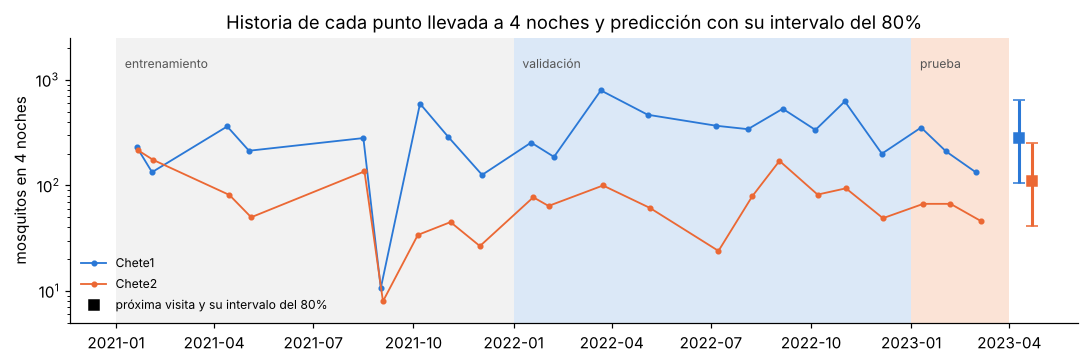

In [ ]:
media_t, desv_t = escalas(modelable, feats)
theta_todo = ajustar_poisson(matriz(modelable, media_t, desv_t, feats), modelable["total"].values, modelable["esfuerzo"].values)

nuevo = camp[camp["localidad"] == "Cheté"].groupby("cluster").tail(1).copy()
for i, fila in nuevo.iterrows():
    hist = camp[camp["cluster"] == fila["cluster"]]
    nuevo.loc[i, "lag1"] = hist["ltasa"].iloc[-1]
    nuevo.loc[i, "historico"] = hist["ltasa"].mean()
    nuevo.loc[i, "neiv_hist"] = hist["neivai"].sum() / hist["total"].sum()
nuevo["regional"] = camp.groupby("cluster")["ltasa"].last().mean()
nuevo["sin_mes"], nuevo["cos_mes"] = np.sin(2 * np.pi * 4 / 12), np.cos(2 * np.pi * 4 / 12)   # visita en abril
nuevo["esfuerzo"] = 4.0
nuevo["prediccion"] = predecir(theta_todo, matriz(nuevo, media_t, desv_t, feats), nuevo["esfuerzo"].values)
nuevo["bajo_80"], nuevo["alto_80"] = intervalo(nuevo["prediccion"])
print("coeficientes con todas las campañas", pd.Series(theta_todo[1:], index=feats).round(3).to_dict())
print(nuevo[["cluster"] + feats + ["prediccion", "bajo_80", "alto_80"]].round(2).to_string(index=False))

# total de Cheté: en cada simulación se sortea una ronda de validación y los dos errores salen de esa ronda
errores_ronda = [val.loc[val["ronda"] == r, "error_log"].values for r in rondas_val]
n_sim = 20000
sim = np.zeros(n_sim)
for i in range(n_sim):
    e = rng.choice(errores_ronda[rng.integers(len(errores_ronda))], 2, replace=False)
    sim[i] = np.sum((nuevo["prediccion"].values + 1) * np.exp(e) - 1)
pares_chete = val[val["localidad"] == "Cheté"].pivot_table(index="ronda", columns="cluster", values="error_log").dropna()
print("correlación entre los errores de Chete1 y Chete2 en la misma ronda", round(pares_chete.corr().iloc[0, 1], 2), "en", len(pares_chete), "rondas")
print("Cheté total, mediana", round(np.median(sim)), " intervalo del 80%", np.quantile(sim, [0.1, 0.9]).round(0))
print("promedio del sitio", round(((10 ** nuevo["historico"] - 1) * 4).sum()), " tasa típica de Timbiquí", round(camp["tasa"].median() * 4 * 2))
for umbral in [500, 700, 1000]:
    print("probabilidad de superar", umbral, round(np.mean(sim > umbral), 2))

fig, ax = plt.subplots(figsize=(10, 3.4))
for x0, x1, color, nombre in [("2021-01-01", "2022-01-01", "#f2f2f2", "entrenamiento"), ("2022-01-01", corte, "#dbe8f7", "validación"), (corte, "2023-04-01", "#fbe3d6", "prueba")]:
    ax.axvspan(pd.Timestamp(x0), pd.Timestamp(x1), color=color, lw=0)
    ax.text(pd.Timestamp(x0) + pd.Timedelta(days=8), 1300, nombre, fontsize=8, color="#555555")
for k, (c, col) in enumerate([("Chete1", azul), ("Chete2", naranja)]):
    s = camp[camp["cluster"] == c]
    ax.plot(s["inicio"], s["tasa"] * 4, "o-", color=col, ms=3, lw=1.2, label=c)
    f = nuevo[nuevo["cluster"] == c].iloc[0]
    ax.errorbar(pd.Timestamp("2023-04-10") + pd.Timedelta(days=12 * k), f["prediccion"],
                yerr=[[f["prediccion"] - f["bajo_80"]], [f["alto_80"] - f["prediccion"]]], fmt="s", color=col, ms=7, capsize=4, lw=2)
ax.plot([], [], "s", color="k", label="próxima visita y su intervalo del 80%")
ax.set_yscale("log")
ax.set_ylim(5, 2500)
ax.set_ylabel("mosquitos en 4 noches")
ax.set_title("Historia de cada punto llevada a 4 noches y predicción con su intervalo del 80%")
ax.legend(frameon=False, loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

Para la próxima visita de 4 noches el modelo predice 284 mosquitos en Chete 1 (intervalo del 80% de 106 a 646) y 111 en Chete 2 (de 41 a 254). Los dos juntos dan una mediana de 406, con un intervalo del 80% entre 196 y 825. La probabilidad de superar 500 mosquitos es 0.37, la de superar 700 es 0.17 y la de superar 1000 es 0.04. En la validación los errores de Chete 1 y Chete 2 en una misma ronda tienen correlación 0.46 (10 rondas), lo que justifica sortearlos juntos. Como comparación, el promedio del sitio da 322; la tasa típica de Timbiquí, para 4 noches y 2 conglomerados, da 576; la mediana de las rondas de 2021 y 2022 en Cheté fue 417 (sección 3.5), y la estimación de Fermi inicial fue 192. En la gráfica el intervalo de Chete 1 se ve más ancho en mosquitos porque el intervalo es multiplicativo.

Por lo visto en las secciones 4.12 y 4.13, lo más probable es que la cifra de Chete 2 se pase, en 2023 el modelo sobrepredijo Chete 2 en las tres campañas y Chete 1 en dos de tres. Si eso sigue, el total real quedaría más cerca del promedio del sitio que de la mediana del modelo. Esto es una lectura de los sesgos, no algo que hayamos probado.
##Sugerencia para el equipo
 los frascos dependen del protocolo y no del conteo. Si es un frasco por recolector y por hora, como pensamos, son 96 por conglomerado y 192 para Cheté, y hay que confirmar esa cifra antes de comprar. La sílica gel y las horas de laboratorio sí dependen del conteo, y según la simulación preparar para unos 825 mosquitos cubre 9 de cada 10 visitas.
##¿Le sirve el modelo al equipo?
Le da una cifra con un intervalo validado, que cubrió al 77% en la comprobación secuencial de 2022 y al 88% en 2023. Esa cifra casi la reproduce el promedio de lo que ha capturado cada punto, y el modelo tiende a pasarse cuando hay pocos mosquitos. Si el equipo cambia de vivienda o de conglomerado, el modelo no sabe nada del sitio nuevo. Tampoco sabe qué intervención está activa en cada conglomerado.

# 5. Lo que nos preguntamos en campo

En el mapa de calor algunas columnas se veían más claras para todos los sitios a la vez. Nuestra pregunta es si las capturas de toda la región suben y bajan juntas, como si las moviera algo común como la lluvia, o si cada sitio va por su lado. Si van juntas, una medición regional ayudaría a planear todas las campañas.

Usamos la anomalía de la sección 3.3, $a_i = y_i-\bar y_{c(i)}$, y medimos qué fracción de ella explica el promedio de su ronda:

$$R^2_{\text{ronda}} = 1-\frac{\sum_i \left(a_i-\bar a_{r(i)}\right)^2}{\sum_i a_i^2}.$$

Es el R² de la sección 3.1 aplicado a las anomalías, así que, a diferencia del de la sección 3.3, el denominador es solo la variación que queda después de quitar el conglomerado. Para saber cuánto sale por azar barajamos las rondas dentro de cada conglomerado. Así cada sitio conserva sus valores pero se rompe la coincidencia en el tiempo. Lo calculamos con todos los sitios, sin las dos rondas más atípicas y para cada especie por separado.

                        R2 ronda  por azar      p
todos los sitios           0.234     0.063  0.000
sin 2021-09 ni 2022-03     0.163     0.062  0.000
sitios de albimanus        0.549     0.250  0.001
sitios de neivai           0.368     0.102  0.000
correlación entre las curvas de albimanus y neivai 0.06
segmento  albimanus  mixto  neivai
ronda                             
2021-09       -0.74  -0.16   -0.11
2022-03        0.16  -0.22   -0.69
correlación de la curva regional con la de la ronda anterior 0.26


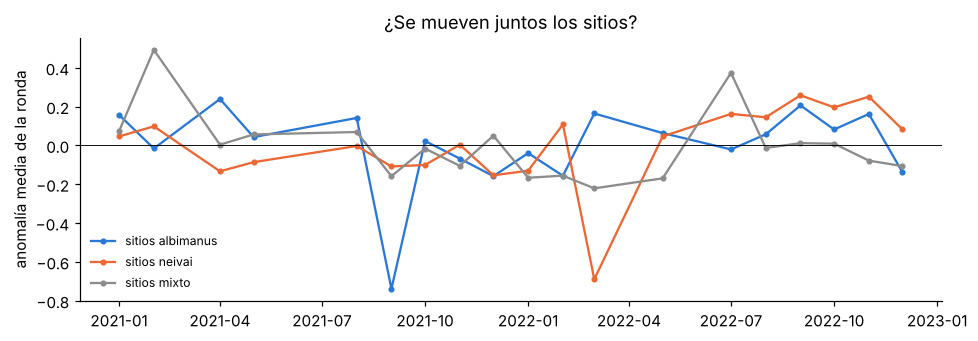

In [ ]:
rng = np.random.default_rng(5)

def r2_ronda_con_nulo(datos, n=1000):
    obs = r2_grupo(datos, "ronda", y="anomalia")
    azar = []
    for b in range(n):
        barajado = datos.copy()
        barajado["ronda"] = barajado.groupby("cluster")["ronda"].transform(lambda s: rng.permutation(s.values))
        azar.append(r2_grupo(barajado, "ronda", y="anomalia"))
    return obs, np.mean(azar), np.mean(np.array(azar) >= obs)

subconjuntos = {
    "todos los sitios": dev,
    "sin 2021-09 ni 2022-03": dev[~dev["ronda"].astype(str).isin(["2021-09", "2022-03"])],
    "sitios de albimanus": dev[dev["segmento"] == "albimanus"],
    "sitios de neivai": dev[dev["segmento"] == "neivai"],
}
sincronia = pd.DataFrame({k: r2_ronda_con_nulo(v) for k, v in subconjuntos.items()}, index=["R2 ronda", "por azar", "p"]).T
print(sincronia.round(3))

curvas = dev.groupby(["ronda", "segmento"])["anomalia"].mean().unstack()
print("correlación entre las curvas de albimanus y neivai", round(curvas["albimanus"].corr(curvas["neivai"]), 2))
print(curvas.loc[[pd.Period("2021-09", "M"), pd.Period("2022-03", "M")]].round(2))
regional = dev.groupby("ronda")["anomalia"].mean()
print("correlación de la curva regional con la de la ronda anterior", round(regional.autocorr(1), 2))

fig, ax = plt.subplots(figsize=(9, 3.2))
for s, c in [("albimanus", azul), ("neivai", naranja), ("mixto", gris)]:
    ax.plot(curvas.index.to_timestamp(), curvas[s], "o-", color=c, ms=3, lw=1.5, label="sitios " + s)
ax.axhline(0, color="k", lw=0.6)
ax.set_ylabel("anomalía media de la ronda")
ax.legend(frameon=False, fontsize=8)
ax.set_title("¿Se mueven juntos los sitios?")
plt.tight_layout()
plt.show()

Las capturas sí se mueven juntas. El promedio de cada ronda explica el 23% de las anomalías, cuando por azar esperaríamos un 6%, y el resultado se mantiene sin las dos rondas más atípicas (16% contra 6%). Es lo mismo que vimos en la sección 3.3 desde otro ángulo: el conglomerado explica el 44%, la ronda el 23% de lo que queda, y 0.44 + 0.23 × 0.56 ≈ 0.57, que es el R² de conglomerado más ronda.

Pero no todos se mueven igual. La curva de los sitios de An. albimanus casi no se parece a la de los de An. neivai (correlación 0.06). En septiembre de 2021 los sitios de albimanus cayeron mucho (anomalía de −0.74) y los de neivai casi nada (−0.11), y en marzo de 2022 pasó lo contrario (−0.69 en neivai y +0.16 en albimanus). Dentro de cada especie la sincronía es mayor que por azar, observando 0.55 contra 0.25 en los 4 sitios de albimanus y 0.37 contra 0.10 en los 10 de neivai. Nuestra lectura, que es una inferencia, es que algo común en cada mes afecta distinto a cada especie. Podría ser que An. neivai y An. albimanus se críen en sitios distintos y respondan distinto a la lluvia, pero es una hipótesis que habría que confirmar con nuevas medidad.

Para planear esto tiene dos consecuencias. Una medición del mismo mes, como la lluvia de los días anteriores, podría explicar parte de lo que pasa en cada campaña, y es la medición que agregaríamos (un pluviómetro en la vereda o la estación meteorologica más cercana). En cambio, la ronda anterior de la región sirve poco para anticipar la siguiente, porque la curva regional se parece poco a la de la ronda anterior (0.26) y porque promedia dos especies que no se mueven igual. Esto explica que la variable regional, que promedia la campaña anterior de todos los conglomerados, no fuese seleccionada.

# 6. Conclusiones

Qué esperábamos y qué encontramos. Esperábamos traer 192 mosquitos, entre 96 y 576, y pensábamos que lo que más pesaría sería la cercanía al agua estancada y la diferencia entre dentro y fuera de la casa. En 2021 y 2022 los dos puntos de Cheté juntos trajeron una mediana de 417 mosquitos en 4 noches, casi todos An. albimanus. El esfuerzo nominal que supusimos coincide con el del estudio (48 horas de captura por noche), así que la cifra central falló sobre todo por la tasa, que fue de 2.2 mosquitos por recolector y hora y no de 1. El agua no se puede medir con estos datos, así que no sabemos si es lo que más pesa. De lo que sí se puede medir, lo que más pesa es el punto de captura, y eso podría reflejar en parte la cercanía al agua
Para la segemnatcion fuimos de lo general a lo particular. Los tres municipios están dominados por An. neivai, pero Timbiquí tiene más An. albimanus que Guapi y en Santa Bárbara pesa más la ronda que el conglomerado, así que trabajamos con Timbiquí. Ahí los 16 conglomerados se separan por especie en 4 sitios de An. albimanus (Cheté y Coteje), 2 mixtos y 10 de An. neivai, siguiendo un gradiente geográfico, de modo que Cheté no representa al municipio. El conglomerado explica el 44% de la variación de la tasa, mientras que las noches, la fase y quién registra no se distinguen del azar. Dentro de Cheté, Chete 1 captura unas 3.8 veces más que Chete 2 en 18 de 19 rondas, a 227 metros, pero esa diferencia no estaba en la línea base (razón 1.1).

Qué predecimos y cómo. Predecimos el total de mosquitos de la próxima campaña de cada punto con una regresión de Poisson entrenada con descenso del gradiente. La selección de variables en la validación de 2022 dejó solo dos: el promedio histórico del punto y su última campaña. La regla se aprende con los 16 conglomerados de Timbiquí y se aplica al historial de Chete 1 y Chete 2. Para la próxima visita de 4 noches predecimos 284 mosquitos en Chete 1 y 111 en Chete 2, unos 406 en total, con un 80% de probabilidad de estar entre 196 y 825 y un 4% de superar 1000. Los frascos no se predicen porque los fija el protocolo.

Qué tan bien funciona. En la validación de 2022 deja el 70% de las campañas dentro de un factor 2. Le gana a la tasa típica y a la regresión lineal, pero no se distingue del promedio de cada sitio, y en las 48 campañas de 2023 el promedio del sitio quedó algo mejor (81% contra 79%). No hay sobreajuste, porque el acierto en entrenamiento (62%) no supera al de validación ni al de prueba; lo que limita al modelo es el ruido entre campañas. Su sesgo es que acerca cada sitio al promedio de Timbiquí. En Cheté se queda corto en Chete 1 y se pasa en Chete 2, y en 2023 sobrepredijo 5 de las 6 campañas. Por eso la cifra de Chete 2 probablemente es alta, y el promedio del sitio (322 para los dos puntos) es una cota baja razonable. El intervalo cubrió al 77% en la comprobación secuencial de 2022 y al 88% de las campañas de 2023, y casi todo su ancho viene del ruido entre campañas y no de los coeficientes.

Nuestra pregunta. Las capturas de la región sí suben y bajan juntas (la ronda explica el 23% de las anomalías, contra 6% por azar), pero los sitios de An. albimanus y los de An. neivai siguen curvas distintas. Una medición del mismo mes, como la lluvia, ayudaría a entender cada campaña. La ronda anterior de la región no sirve para predecir la siguiente.

Durante el camino cambiamos varias desiciones. Empezamos con todo el estudio y terminamos con Timbiquí, porque los municipios difieren en especie y en qué variable pesa más. Pensábamos comparar dentro contra fuera de la casa, pero ese dato no se publicó y pasamos a comparar puntos de captura. Pensábamos usar el esfuerzo tal como venía, pero cada especie trae su propio número de noches y tomamos el mayor. Pensábamos que eventDate era confiable, pero en seis campañas de Timbiquí el año estaba mal y lo corregimos con el orden de las visitas. Pensábamos usar el intervalo de la Poisson, pero con una dispersión de 141 no era válido y lo reemplazamos por los errores de validación. Por último, la selección redujo el modelo de seis variables a dos.

## Limitaciones.

 Es un ensayo de intervención y la tabla no dice qué brazo recibió cada conglomerado ni trae la fase. Por eso la diferencia entre Chete 1 y Chete 2, y cualquier cambio en el tiempo, pueden mezclar el efecto del sitio con el de la intervención, y solo hay 2 rondas de línea base. La tabla no trae vivienda, hora, dentro o fuera, ni lluvia, y los nombres de las personas van con el período y no con cada captura. Los frascos por conglomerado son una inferencia. Además, la evaluación final no fue ciega. Una primera versión con todo el estudio ya mostraba las campañas de 2023; el alcance de Timbiquí se decidió después, la corrección del año se encontró después de varias ejecuciones, y la selección de variables y los complementos del intervalo se hicieron conociendo los resultados de 2023. Las cifras de la prueba final hay que leerlas con esa reserva.
##Preguntas que estos datos no responden.
 Qué pasa hora por hora, cuánto se pica dentro y fuera de la casa, si siempre se muestreó la misma vivienda, qué brazo recibió cada conglomerado y desde cuándo, qué efecto tuvieron los mosquiteros y el rociado, y cuántos mosquitos estaban infectados. La descripción del estudio dice que se buscó la infección natural por Plasmodium y la paridad de las hembras, pero esos resultados no están en la tabla que hemos analizado.